# Machine Learning Capstone Project — Clustering Track
### 23CSE301 Machine Learning | Review 2 Evaluation
**Dataset**: Amazon Sales & Reviews Dataset (`amazon.csv`)  
**Objective**: End-to-end unsupervised clustering pipeline to segment products based on pricing, discounts, ratings, and customer review volume without using labels during training.

## 1. Imports & Setup

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')
os.environ['OMP_NUM_THREADS'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage

# Plot configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Dataset Loading & Exploratory Data Analysis (EDA)

In [2]:
# Load the dataset
df_raw = pd.read_csv('amazon.csv')
print("Dataset Shape:", df_raw.shape)
df_raw.head(3)

Dataset Shape: (1465, 16)


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...


In [3]:
# Data Audit: Datatypes and Missing Values
audit = pd.DataFrame({
    'Data Type': df_raw.dtypes,
    'Non-Null Count': df_raw.notnull().sum(),
    'Null Count': df_raw.isnull().sum(),
    'Unique Values': df_raw.nunique()
})
audit

,Data Type,Non-Null Count,Null Count,Unique Values
product_id,str,1465,0,1351
product_name,str,1465,0,1337
category,str,1465,0,211
discounted_price,str,1465,0,550
actual_price,str,1465,0,449
discount_percentage,str,1465,0,92
rating,str,1465,0,28
rating_count,str,1463,2,1143
about_product,str,1465,0,1293
user_id,str,1465,0,1194


**Observation (A1 Audit):**
The dataset contains 1,465 products and 16 columns. Numerical features (`discounted_price`, `actual_price`, `discount_percentage`, `rating`, `rating_count`) are stored as strings due to currency symbols (`₹`), commas, and percentage signs (`%`). In `rating`, row 1279 has an invalid character (`'|'`), and `rating_count` has 2 missing values.

In [4]:
# Data Parsing for EDA
df = df_raw.copy()

df['discounted_price_clean'] = pd.to_numeric(
    df['discounted_price'].astype(str).str.replace('₹', '', regex=False).str.replace(',', '', regex=False).str.strip(),
    errors='coerce'
)

df['actual_price_clean'] = pd.to_numeric(
    df['actual_price'].astype(str).str.replace('₹', '', regex=False).str.replace(',', '', regex=False).str.strip(),
    errors='coerce'
)

df['discount_percentage_clean'] = pd.to_numeric(
    df['discount_percentage'].astype(str).str.replace('%', '', regex=False).str.strip(),
    errors='coerce'
)

df['rating_clean'] = pd.to_numeric(df['rating'].replace('|', np.nan), errors='coerce')
df['rating_clean'] = df['rating_clean'].fillna(df['rating_clean'].median())

df['rating_count_clean'] = pd.to_numeric(
    df['rating_count'].astype(str).str.replace(',', '', regex=False).str.replace(' ', '', regex=False),
    errors='coerce'
)
df['rating_count_clean'] = df['rating_count_clean'].fillna(df['rating_count_clean'].median())

df['main_category'] = df['category'].apply(lambda x: str(x).split('|')[0] if pd.notnull(x) else 'Other')

df[['discounted_price_clean', 'actual_price_clean', 'discount_percentage_clean', 'rating_clean', 'rating_count_clean']].describe().round(2)

,discounted_price_clean,actual_price_clean,discount_percentage_clean,rating_clean,rating_count_clean
count,1465.00,1465.00,1465.00,1465.00,1465.00
mean,3125.31,5444.99,47.69,4.10,18277.63
std,6944.30,10874.83,21.64,0.29,42727.40
min,39.00,39.00,0.00,2.00,2.00
25%,325.00,800.00,32.00,4.00,1191.00
50%,799.00,1650.00,50.00,4.10,5179.00
75%,1999.00,4295.00,63.00,4.30,17325.00
max,77990.00,139900.00,94.00,5.00,426973.00


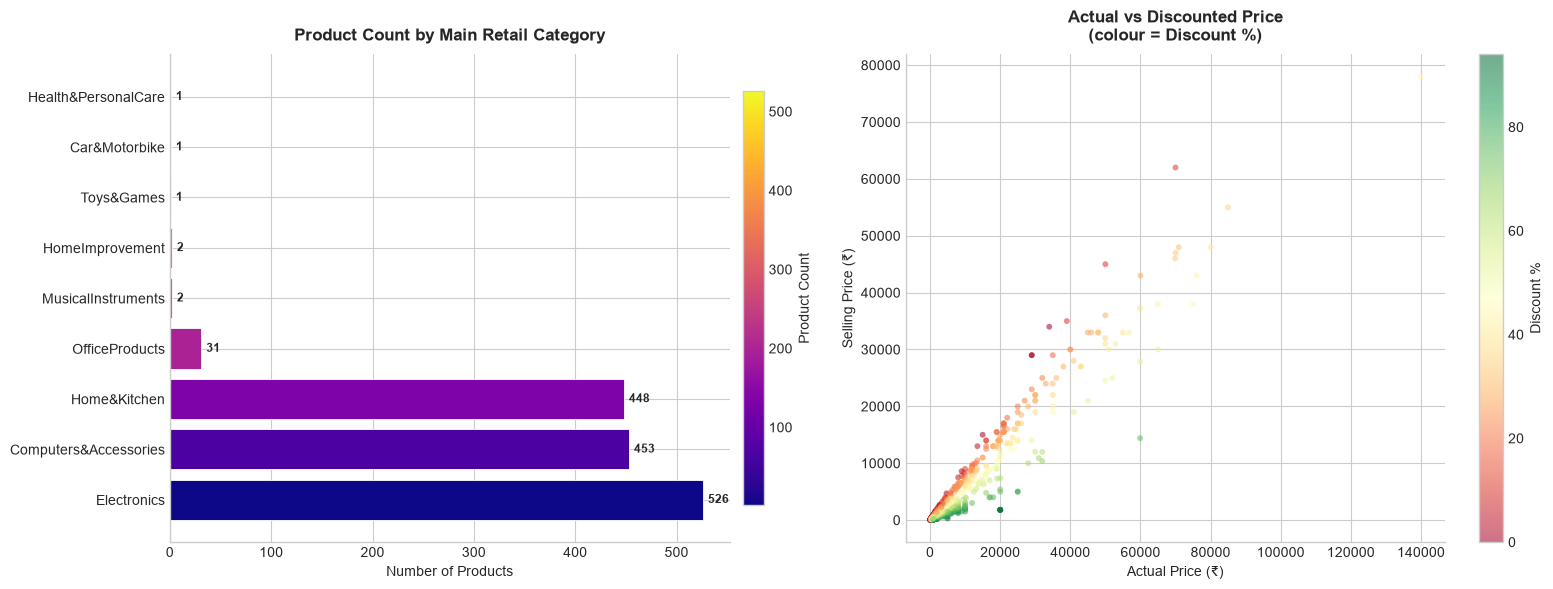

In [5]:
# EDA Visualisations: Category Distribution & Numerical Distributions
import matplotlib.colors as mcolors
import matplotlib.cm as cm_module
from matplotlib import colormaps as mpl_cmaps

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Category Distribution — gradient colormap
cat_counts = df['main_category'].value_counts()
n_cats = len(cat_counts)
cmap_cat = mpl_cmaps['plasma'].resampled(n_cats)
bar_colors = [cmap_cat(i) for i in range(n_cats)]
bars = axes[0].barh(cat_counts.index, cat_counts.values,
                    color=bar_colors, edgecolor='white', linewidth=0.6)
for bar, val in zip(bars, cat_counts.values):
    axes[0].text(val + 5, bar.get_y() + bar.get_height()/2,
                 str(val), va='center', ha='left', fontsize=8.5, fontweight='bold')
norm = mcolors.Normalize(vmin=cat_counts.values.min(), vmax=cat_counts.values.max())
sm = cm_module.ScalarMappable(cmap='plasma', norm=norm)
sm.set_array([])
plt.colorbar(sm, ax=axes[0], orientation='vertical', label='Product Count', shrink=0.85, pad=0.02)
axes[0].set_title('Product Count by Main Retail Category', fontweight='bold', fontsize=12, pad=10)
axes[0].set_xlabel('Number of Products')
axes[0].spines[['top','right']].set_visible(False)

# 2. Actual vs Discounted Price Scatter — coloured by Discount%
sc = axes[1].scatter(
    df['actual_price_clean'], df['discounted_price_clean'],
    c=df['discount_percentage_clean'], cmap='RdYlGn',
    alpha=0.55, s=18, edgecolors='none'
)
plt.colorbar(sc, ax=axes[1], label='Discount %')
axes[1].set_title('Actual vs Discounted Price\n(colour = Discount %)', fontweight='bold', fontsize=12, pad=10)
axes[1].set_xlabel('Actual Price (\u20b9)'); axes[1].set_ylabel('Selling Price (\u20b9)')
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('eda_category_colormap.png', dpi=150, bbox_inches='tight')
plt.show()


### 2a. Interactive Exploratory Visualisation (Plotly)
Hover over any data point to see full product details. Use the cluster dropdown to filter segments in real time.

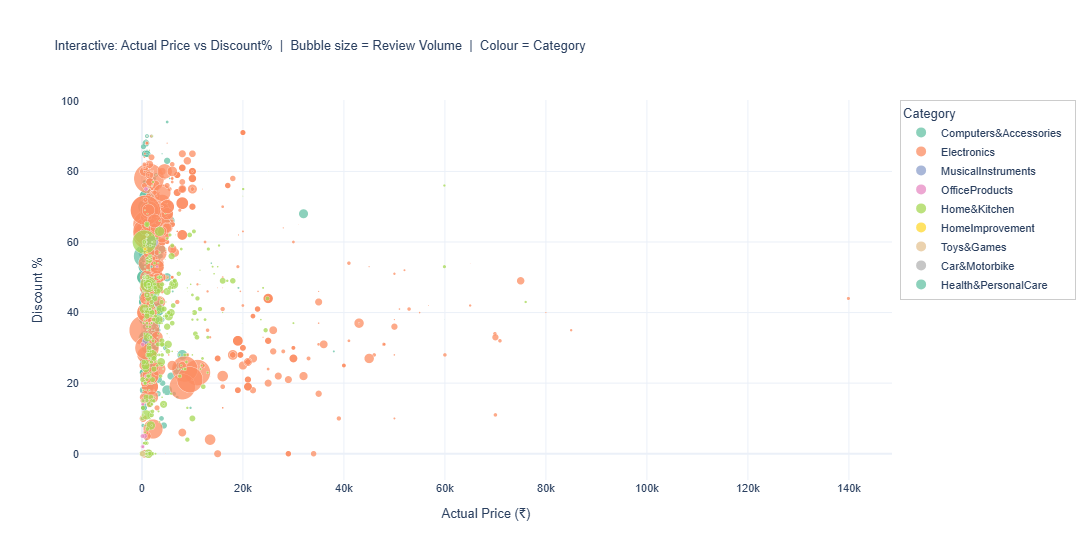

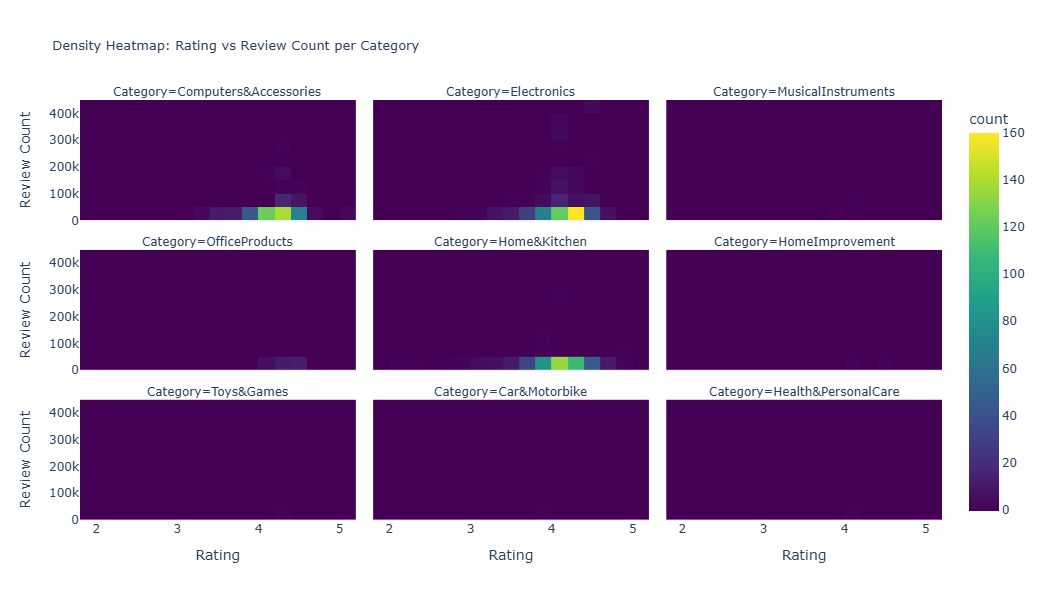

Interactive Plotly charts rendered above.


In [6]:
# ── Interactive Scatter: Actual Price vs Discount% coloured by Category ──────
try:
    import plotly.express as px
    import plotly.graph_objects as go

    df_plot = df[['product_name','main_category',
                  'actual_price_clean','discounted_price_clean',
                  'discount_percentage_clean','rating_clean',
                  'rating_count_clean']].dropna().copy()
    df_plot.columns = ['Product','Category','Actual Price','Selling Price',
                        'Discount %','Rating','Review Count']
    df_plot['Product'] = df_plot['Product'].str[:60]   # trim long names

    fig = px.scatter(
        df_plot,
        x='Actual Price',
        y='Discount %',
        color='Category',
        size='Review Count',
        size_max=30,
        hover_name='Product',
        hover_data={'Selling Price': True, 'Rating': True,
                    'Actual Price': True, 'Review Count': True},
        color_discrete_sequence=px.colors.qualitative.Set2,
        title='Interactive: Actual Price vs Discount%  |  Bubble size = Review Volume  |  Colour = Category',
        labels={'Actual Price': 'Actual Price (₹)', 'Discount %': 'Discount %'},
        template='plotly_white',
        opacity=0.75
    )
    fig.update_layout(
        height=560,
        legend=dict(title='Category', orientation='v',
                    x=1.01, y=1, bgcolor='rgba(255,255,255,0.85)',
                    bordercolor='#ccc', borderwidth=1),
        title_font_size=13,
        font=dict(family='Inter, Arial', size=11),
        hovermode='closest'
    )
    fig.update_traces(marker=dict(line=dict(width=0.4, color='white')))
    fig.show()

    # ── Second interactive: Rating vs Review Count heatmap density ────────────
    fig2 = px.density_heatmap(
        df_plot,
        x='Rating',
        y='Review Count',
        facet_col='Category',
        facet_col_wrap=3,
        color_continuous_scale='Viridis',
        title='Density Heatmap: Rating vs Review Count per Category',
        template='plotly_white',
        nbinsx=20, nbinsy=20
    )
    fig2.update_layout(height=600, title_font_size=13)
    fig2.show()

    print('Interactive Plotly charts rendered above.')
except ImportError:
    print('plotly not installed. Run: pip install plotly')
    print('Falling back to static chart...')
    fig_s, ax_s = plt.subplots(figsize=(12, 6))
    cats = df['main_category'].unique()
    cmap_s = plt.cm.get_cmap('Set2', len(cats))
    for ci, cat in enumerate(cats):
        m = df['main_category'] == cat
        ax_s.scatter(df.loc[m,'actual_price_clean'], df.loc[m,'discount_percentage_clean'],
                     c=[cmap_s(ci)], label=cat, alpha=0.5, s=15)
    ax_s.set_xlabel('Actual Price (₹)'); ax_s.set_ylabel('Discount %')
    ax_s.set_title('Actual Price vs Discount % by Category')
    ax_s.legend(fontsize=7, loc='best')
    plt.tight_layout(); plt.show()


**Observation (EDA):**
Over 97% of products belong to Electronics (35.9%), Computers & Accessories (30.9%), and Home & Kitchen (30.6%). The price scatter shows dense concentration in budget items (< ₹5,000) with a long tail of high-value electronics up to ₹60,000+.

## 3. Preprocessing & Feature Engineering

In [7]:
# Duplicate check and removal
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
rows_after = len(df)
print(f"Duplicate Check: Rows before = {rows_before}, Rows after = {rows_after}, Removed = {rows_before - rows_after}")

Duplicate Check: Rows before = 1465, Rows after = 1465, Removed = 0


In [8]:
# Feature Engineering with justification
# 1. discount_amount: Monetary rupee savings (actual - discounted)
df['discount_amount'] = (df['actual_price_clean'] - df['discounted_price_clean']).clip(lower=0)

# 2. log_rating_count: Log review count to normalize exponential right skew
df['log_rating_count'] = np.log1p(df['rating_count_clean'])

# 3. log_actual_price and log_discounted_price: Log price to normalize wide rupee range
df['log_actual_price'] = np.log1p(df['actual_price_clean'])
df['log_discounted_price'] = np.log1p(df['discounted_price_clean'])

print("Feature engineering complete:")
df[['discount_amount', 'log_rating_count', 'log_actual_price', 'log_discounted_price']].head(3)

# Derive top-level retail category from pipe-delimited category string
df['main_category'] = df['category'].str.split('|').str[0].str.strip()
print('Unique main categories:', df['main_category'].nunique())


Feature engineering complete:
Unique main categories: 9


In [9]:
# Feature Scaling (StandardScaler)
# Justification: K-Means and Hierarchical Clustering use Euclidean distance, which requires zero mean and unit variance.
features_for_clustering = [
    'log_discounted_price',
    'log_actual_price',
    'discount_percentage_clean',
    'rating_clean',
    'log_rating_count'
]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features_for_clustering])

print("Scaled Feature Matrix Shape:", X_scaled.shape)
print("Feature Means (approx 0):", np.round(X_scaled.mean(axis=0), 3))
print("Feature Stds  (approx 1):", np.round(X_scaled.std(axis=0), 3))

Scaled Feature Matrix Shape: (1465, 5)
Feature Means (approx 0): [ 0. -0.  0. -0.  0.]
Feature Stds  (approx 1): [1. 1. 1. 1. 1.]


## 4. Model 1: K-Means Clustering & Optimization
Partitions products into $k$ clusters by minimizing inertia. Optimal cluster count is evaluated across $k \in [2, 10]$ using the Elbow Method and Silhouette scores.

In [10]:
# Hyperparameter search across k in [2, 10]
k_range = range(2, 11)
inertias = []
silhouette_scores_k = []
davies_bouldin_scores_k = []
calinski_harabasz_scores_k = []

print("Running K-Means Hyperparameter Search (k=2 to 10)...")
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_labels = km.fit_predict(X_scaled)
    
    inertias.append(km.inertia_)
    silhouette_scores_k.append(silhouette_score(X_scaled, km_labels))
    davies_bouldin_scores_k.append(davies_bouldin_score(X_scaled, km_labels))
    calinski_harabasz_scores_k.append(calinski_harabasz_score(X_scaled, km_labels))
    print(f" - k={k:2d}: Inertia={km.inertia_:10.2f} | Silhouette={silhouette_scores_k[-1]:.4f} | DB={davies_bouldin_scores_k[-1]:.4f} | CH={calinski_harabasz_scores_k[-1]:8.2f}")

Running K-Means Hyperparameter Search (k=2 to 10)...
 - k= 2: Inertia=   5328.95 | Silhouette=0.2517 | DB=1.4585 | CH=  547.99
 - k= 3: Inertia=   4346.73 | Silhouette=0.2289 | DB=1.4694 | CH=  500.86
 - k= 4: Inertia=   3736.58 | Silhouette=0.2339 | DB=1.3359 | CH=  467.69
 - k= 5: Inertia=   3275.13 | Silhouette=0.2325 | DB=1.3085 | CH=  451.34
 - k= 6: Inertia=   2983.58 | Silhouette=0.2171 | DB=1.2941 | CH=  424.60
 - k= 7: Inertia=   2725.70 | Silhouette=0.2280 | DB=1.2698 | CH=  410.03
 - k= 8: Inertia=   2513.08 | Silhouette=0.2362 | DB=1.2334 | CH=  398.54
 - k= 9: Inertia=   2346.08 | Silhouette=0.2325 | DB=1.2054 | CH=  386.25
 - k=10: Inertia=   2217.60 | Silhouette=0.2262 | DB=1.2384 | CH=  372.34


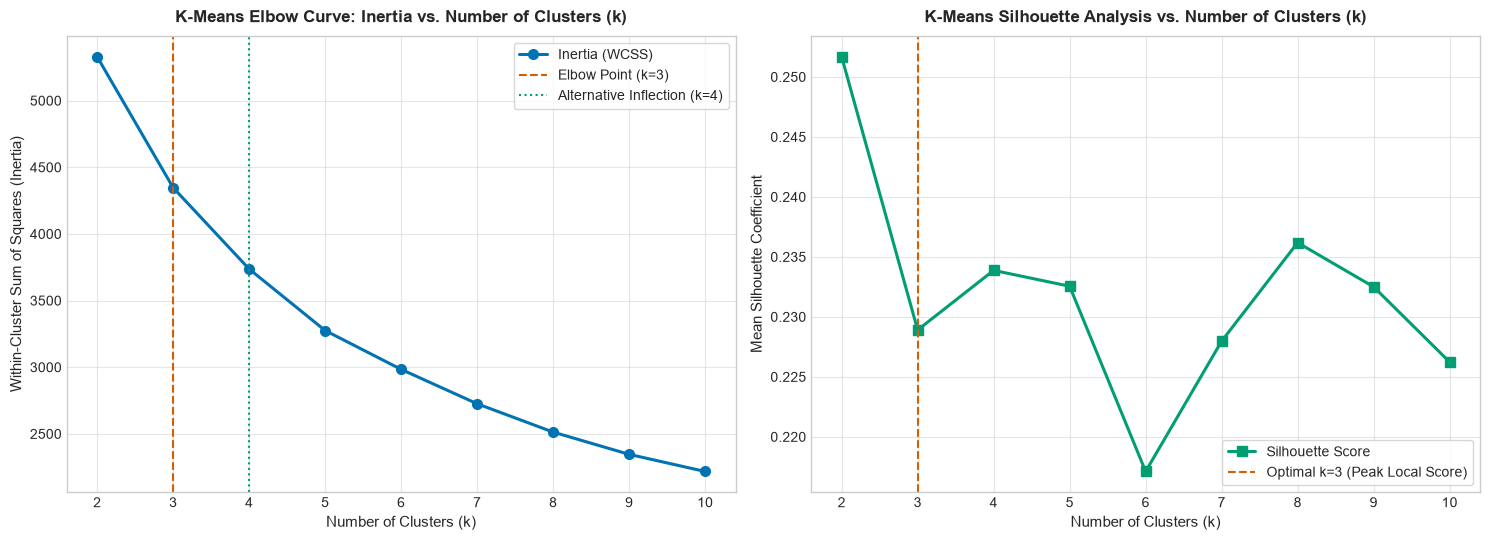

In [11]:
# Plotting the Elbow Curve and Silhouette Profile
palette = sns.color_palette('colorblind')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot 1: Inertia (Elbow Curve)
ax1.plot(k_range, inertias, marker='o', linewidth=2.2, markersize=7, color=palette[0], label='Inertia (WCSS)')
ax1.axvline(x=3, color=palette[3], linestyle='--', linewidth=1.5, label='Elbow Point (k=3)')
ax1.axvline(x=4, color=palette[2], linestyle=':', linewidth=1.5, label='Alternative Inflection (k=4)')
ax1.set_title("K-Means Elbow Curve: Inertia vs. Number of Clusters (k)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("Number of Clusters (k)", fontsize=11)
ax1.set_ylabel("Within-Cluster Sum of Squares (Inertia)", fontsize=11)
ax1.set_xticks(k_range)
ax1.legend(loc='upper right', frameon=True)
ax1.grid(True, alpha=0.5)

# Subplot 2: Silhouette Score Profile
ax2.plot(k_range, silhouette_scores_k, marker='s', linewidth=2.2, markersize=7, color=palette[2], label='Silhouette Score')
ax2.axvline(x=3, color=palette[3], linestyle='--', linewidth=1.5, label='Optimal k=3 (Peak Local Score)')
ax2.set_title("K-Means Silhouette Analysis vs. Number of Clusters (k)", fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("Number of Clusters (k)", fontsize=11)
ax2.set_ylabel("Mean Silhouette Coefficient", fontsize=11)
ax2.set_xticks(k_range)
ax2.legend(loc='lower right', frameon=True)
ax2.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

In [12]:
# Fit optimal models for comparison: k=3 (primary) and k=4 (alternative)
kmeans_k3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
labels_km3 = kmeans_k3.labels_

kmeans_k4 = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_scaled)
labels_km4 = kmeans_k4.labels_

print("\nCluster membership distribution for K-Means (k=3):")
for c, count in enumerate(np.bincount(labels_km3)):
    print(f" - Cluster {c}: {count} products ({count/len(X_scaled)*100:.1f}%)")


Cluster membership distribution for K-Means (k=3):
 - Cluster 0: 590 products (40.3%)
 - Cluster 1: 412 products (28.1%)
 - Cluster 2: 463 products (31.6%)


## 5. Model 2: Hierarchical Clustering
Constructs an agglomerative tree using Ward's linkage to reveal nested taxonomic hierarchies. Dendrogram cuts validate the optimal cluster count identified during K-Means optimization.

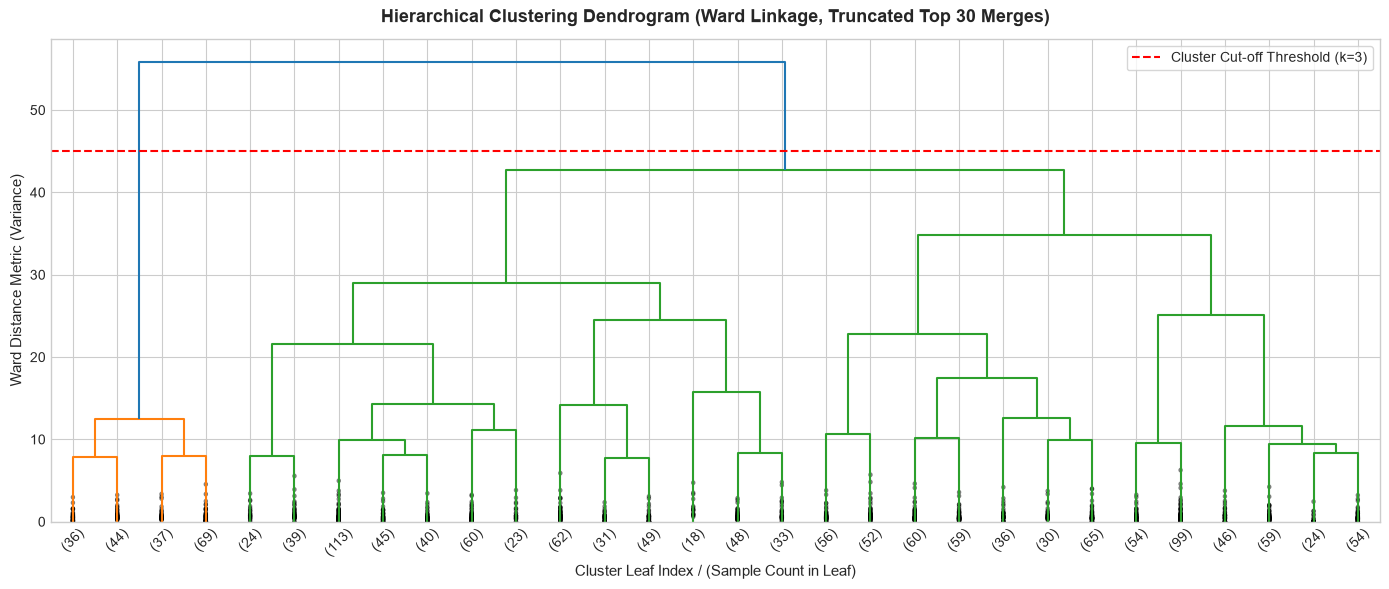

In [13]:
# Compute Hierarchical Linkage Matrix using Ward's method
linkage_ward = linkage(X_scaled, method='ward')

# Generate publication-quality truncated Dendrogram
plt.figure(figsize=(14, 6))
dendro = dendrogram(
    linkage_ward,
    truncate_mode='lastp',
    p=30,                     # Show top 30 merged branches for clean interpretability
    leaf_rotation=45.,
    leaf_font_size=10.,
    show_contracted=True,
    color_threshold=45.0      # Cut-off distance visualizing cluster separation
)

# Annotate cut-off line
plt.axhline(y=45.0, color='red', linestyle='--', linewidth=1.5, label='Cluster Cut-off Threshold (k=3)')
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage, Truncated Top 30 Merges)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Cluster Leaf Index / (Sample Count in Leaf)", fontsize=11)
plt.ylabel("Ward Distance Metric (Variance)", fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

In [14]:
# Fit Agglomerative models for Ward, Complete, and Average linkages at k=3
linkage_methods = ['ward', 'complete', 'average']
agg_models = {}
agg_labels = {}

for method in linkage_methods:
    model = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = model.fit_predict(X_scaled)
    agg_models[method] = model
    agg_labels[method] = labels
    counts = np.bincount(labels)
    print(f"Agglomerative Linkage='{method}': Cluster Counts = {counts.tolist()}")

Agglomerative Linkage='ward': Cluster Counts = [694, 186, 585]
Agglomerative Linkage='complete': Cluster Counts = [512, 14, 939]
Agglomerative Linkage='average': Cluster Counts = [4, 3, 1458]


### 5a. Agglomerative Hierarchical Clustering — Detailed Visualisation
Side-by-side comparison of Ward, Complete, and Average linkage methods with colourmap-enhanced scatter plots and a linkage distance profile.

Fitting t-SNE...
PCA and t-SNE completed successfully.


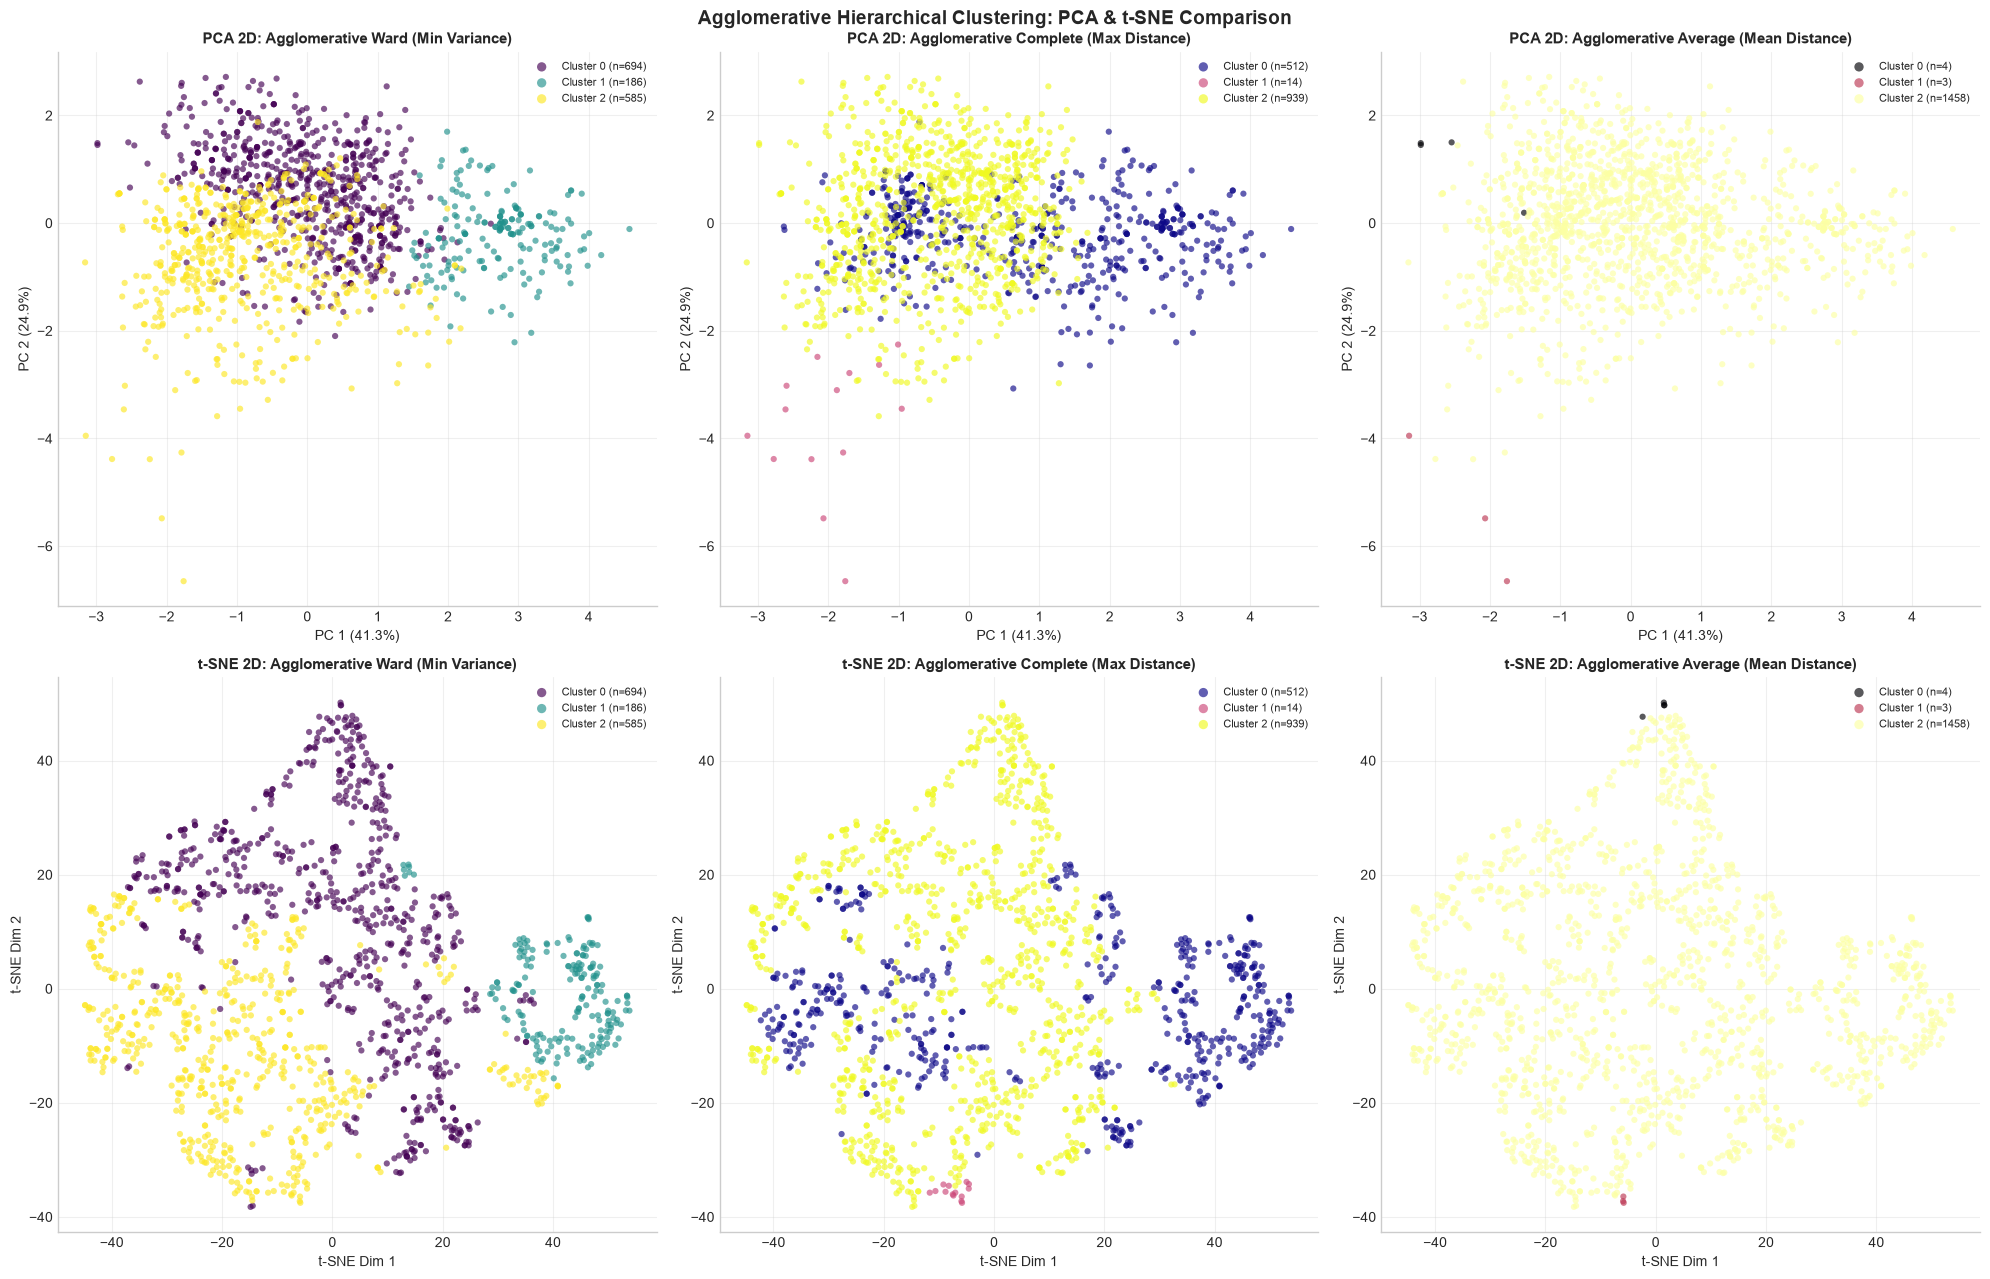

Saved: agglomerative_pca_tsne_comparison.png


In [15]:
# ── 5a. Agglomerative Hierarchical Clustering: Detailed Visual Comparison ──

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps as mpl_cmaps
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 1. Generate PCA coordinates
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_

# 2. Generate t-SNE coordinates
print("Fitting t-SNE...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

print("PCA and t-SNE completed successfully.")

# 3. Configure the plots
fig, axes = plt.subplots(2, 3, figsize=(20, 13))

linkage_names = ['ward', 'complete', 'average']
link_titles = [
    'Ward (Min Variance)',
    'Complete (Max Distance)',
    'Average (Mean Distance)'
]
cmap_names = ['viridis', 'plasma', 'inferno']

# 4. Row 1: PCA scatter plots
for j, (method, title, cm_name) in enumerate(
    zip(linkage_names, link_titles, cmap_names)
):
    ax = axes[0, j]
    lbls = agg_labels[method]

    unique_labels = np.unique(lbls)
    cmap_disc = mpl_cmaps[cm_name].resampled(len(unique_labels))

    for i, k in enumerate(unique_labels):
        mask = lbls == k

        ax.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            color=cmap_disc(i),
            label=f'Cluster {k} (n={mask.sum()})',
            alpha=0.65,
            s=20,
            edgecolor='none'
        )

    ax.set_title(
        f'PCA 2D: Agglomerative {title}',
        fontsize=11,
        fontweight='bold'
    )
    ax.set_xlabel(f'PC 1 ({evr[0] * 100:.1f}%)')
    ax.set_ylabel(f'PC 2 ({evr[1] * 100:.1f}%)')
    ax.legend(fontsize=8, markerscale=1.5)
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# 5. Row 2: t-SNE scatter plots
for j, (method, title, cm_name) in enumerate(
    zip(linkage_names, link_titles, cmap_names)
):
    ax = axes[1, j]
    lbls = agg_labels[method]

    unique_labels = np.unique(lbls)
    cmap_disc = mpl_cmaps[cm_name].resampled(len(unique_labels))

    for i, k in enumerate(unique_labels):
        mask = lbls == k

        ax.scatter(
            X_tsne[mask, 0],
            X_tsne[mask, 1],
            color=cmap_disc(i),
            label=f'Cluster {k} (n={mask.sum()})',
            alpha=0.65,
            s=20,
            edgecolor='none'
        )

    ax.set_title(
        f't-SNE 2D: Agglomerative {title}',
        fontsize=11,
        fontweight='bold'
    )
    ax.set_xlabel('t-SNE Dim 1')
    ax.set_ylabel('t-SNE Dim 2')
    ax.legend(fontsize=8, markerscale=1.5)
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# 6. Final layout and save
fig.suptitle(
    'Agglomerative Hierarchical Clustering: PCA & t-SNE Comparison',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig(
    'agglomerative_pca_tsne_comparison.png',
    dpi=150,
    bbox_inches='tight'
)
plt.show()

print('Saved: agglomerative_pca_tsne_comparison.png')

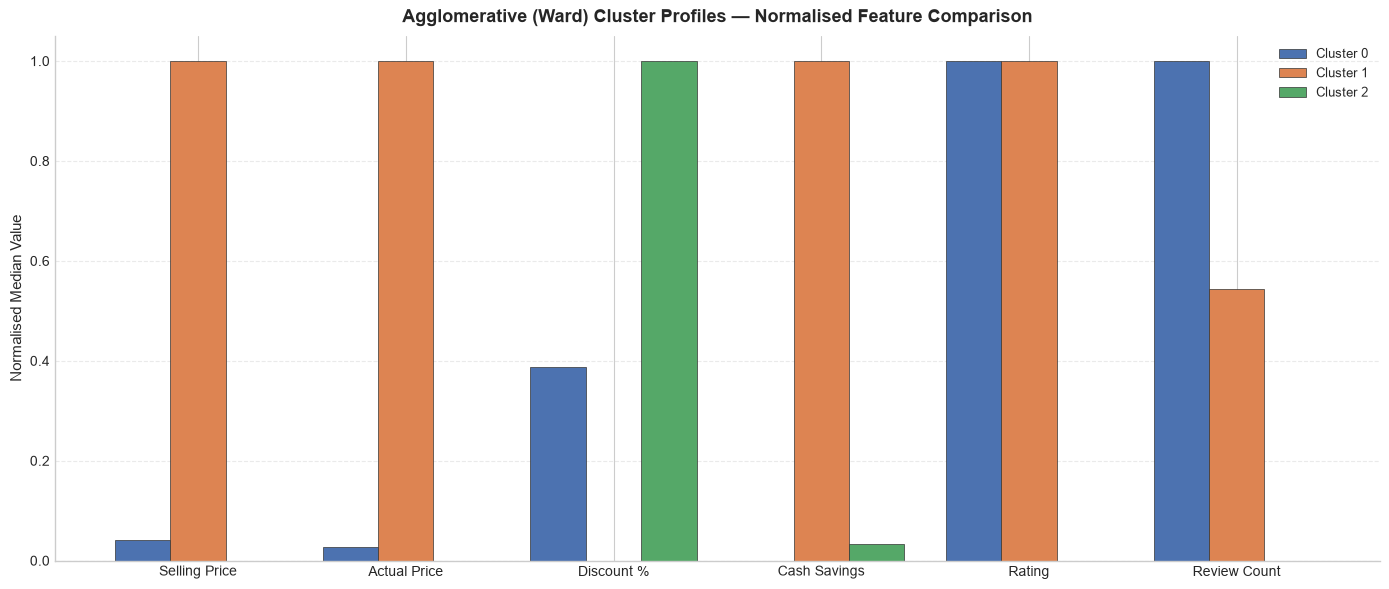

Saved: agglomerative_ward_profiles.png


In [16]:
# ── Agglomerative Ward: Cluster Profile Comparison (Grouped Bars) ────────────
df_agg = df.copy()
df_agg['Cluster_Ward'] = agg_labels['ward']

profile_feats = ['discounted_price_clean','actual_price_clean','discount_percentage_clean',
                 'discount_amount','rating_clean','rating_count_clean']
agg_med = df_agg.groupby('Cluster_Ward')[profile_feats].median()

# Normalise for grouped comparison
agg_med_norm = (agg_med - agg_med.min()) / (agg_med.max() - agg_med.min() + 1e-9)

fig, ax = plt.subplots(figsize=(14, 6))
x_pos = np.arange(len(profile_feats))
n_clusters = len(agg_med_norm)
bar_w = 0.8 / n_clusters
agg_colors = ['#4C72B0', '#DD8452', '#55A868']

for ci, (cluster_id, row) in enumerate(agg_med_norm.iterrows()):
    offset = (ci - n_clusters/2 + 0.5) * bar_w
    ax.bar(x_pos + offset, row.values, width=bar_w, label=f'Cluster {cluster_id}',
           color=agg_colors[ci % len(agg_colors)], edgecolor='#333', linewidth=0.5)

ax.set_xticks(x_pos)
pretty_names = ['Selling Price', 'Actual Price', 'Discount %', 'Cash Savings', 'Rating', 'Review Count']
ax.set_xticklabels(pretty_names, fontsize=10)
ax.set_ylabel('Normalised Median Value', fontsize=11)
ax.set_title('Agglomerative (Ward) Cluster Profiles — Normalised Feature Comparison',
             fontsize=13, fontweight='bold', pad=10)
ax.legend(fontsize=9.5, framealpha=0.8)
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('agglomerative_ward_profiles.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: agglomerative_ward_profiles.png')


## 6. Cluster Validation & Evaluation
Evaluates partition quality using Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index. Balances compact intra-cluster variance against well-separated inter-cluster margins.

In [17]:
# Define dictionary of candidate models
models_to_evaluate = {
    'K-Means (k=3)': labels_km3,
    'K-Means (k=4)': labels_km4,
    'Agglomerative (Ward, k=3)': agg_labels['ward'],
    'Agglomerative (Complete, k=3)': agg_labels['complete'],
    'Agglomerative (Average, k=3)': agg_labels['average']
}

# Compute validation metrics
comparison_records = []

for model_name, labels in models_to_evaluate.items():
    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)
    n_clusts = len(np.unique(labels))

    comparison_records.append({
        'Algorithm / Configuration': model_name,
        'Clusters (k)': n_clusts,
        'Silhouette Score (↑)': sil,
        'Davies-Bouldin Index (↓)': db,
        'Calinski-Harabasz Index (↑)': ch
    })

# Format into summary table
comparison_df = pd.DataFrame(comparison_records)
comparison_df.set_index('Algorithm / Configuration', inplace=True)

print("             UNSUPERVISED CLUSTERING PERFORMANCE BENCHMARK SUMMARY")
print(comparison_df.round(4).to_string())

# Styled display — chained correctly on ONE logical line
(
    comparison_df.style
    .format({
        'Silhouette Score (↑)': '{:.4f}',
        'Davies-Bouldin Index (↓)': '{:.4f}',
        'Calinski-Harabasz Index (↑)': '{:.2f}'
    })
    .highlight_max(subset=['Silhouette Score (↑)', 'Calinski-Harabasz Index (↑)'], color='#d4edda')
    .highlight_min(subset=['Davies-Bouldin Index (↓)'], color='#d4edda')
)

             UNSUPERVISED CLUSTERING PERFORMANCE BENCHMARK SUMMARY
                               Clusters (k)  Silhouette Score (↑)  Davies-Bouldin Index (↓)  Calinski-Harabasz Index (↑)
Algorithm / Configuration                                                                                               
K-Means (k=3)                             3                0.2289                    1.4694                     500.8639
K-Means (k=4)                             4                0.2339                    1.3359                     467.6888
Agglomerative (Ward, k=3)                 3                0.1810                    1.7112                     372.0794
Agglomerative (Complete, k=3)             3                0.1227                    1.8693                     143.0570
Agglomerative (Average, k=3)              3                0.3660                    0.7744                      20.9880


,Clusters (k),Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑)
Algorithm / Configuration,,,,
K-Means (k=3),3,0.2289,1.4694,500.86
K-Means (k=4),4,0.2339,1.3359,467.69
"Agglomerative (Ward, k=3)",3,0.1810,1.7112,372.08
"Agglomerative (Complete, k=3)",3,0.1227,1.8693,143.06
"Agglomerative (Average, k=3)",3,0.3660,0.7744,20.99


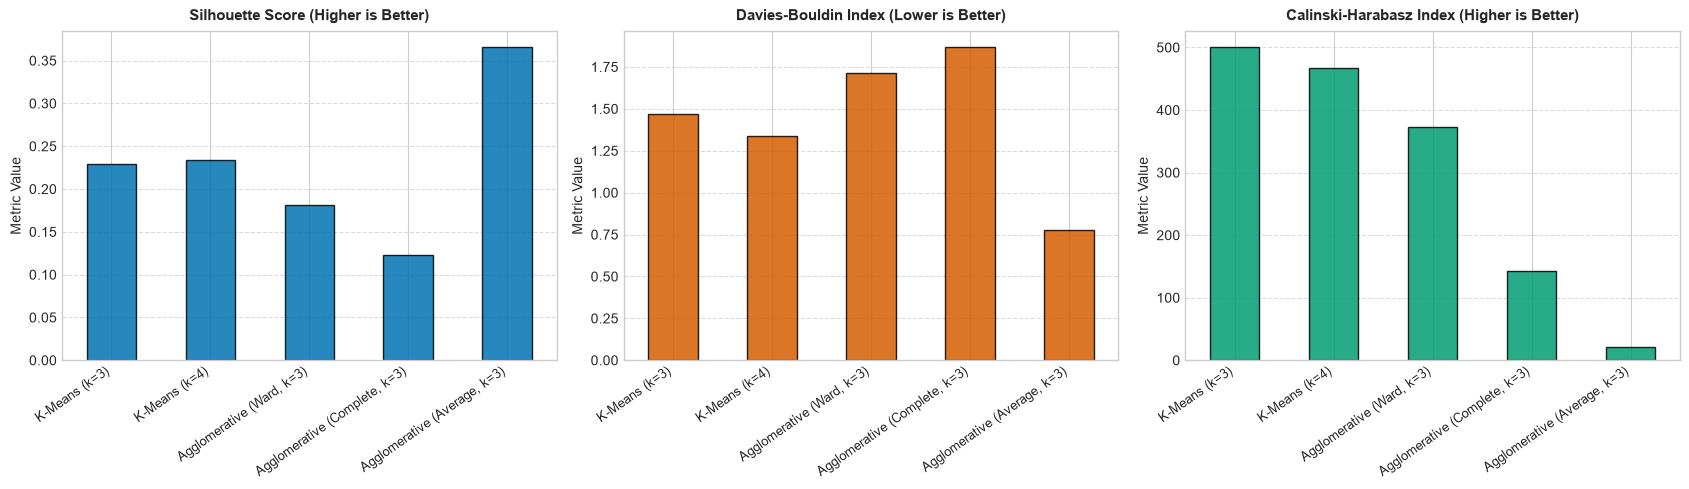

In [18]:
# Comparative Bar Chart
palette = sns.color_palette('colorblind')
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = [
    ('Silhouette Score (↑)', 'Silhouette Score (Higher is Better)', palette[0]),
    ('Davies-Bouldin Index (↓)', 'Davies-Bouldin Index (Lower is Better)', palette[3]),
    ('Calinski-Harabasz Index (↑)', 'Calinski-Harabasz Index (Higher is Better)', palette[2])
]

for ax, (metric_col, title_label, bar_color) in zip(axes, metrics):
    comparison_df[metric_col].plot(kind='bar', ax=ax, color=bar_color, edgecolor='black', alpha=0.85)
    ax.set_title(title_label, fontsize=11, fontweight='bold', pad=8)
    ax.set_ylabel("Metric Value", fontsize=10)
    ax.set_xlabel("")
    ax.set_xticks(range(len(comparison_df.index)))
    ax.set_xticklabels(comparison_df.index, rotation=35, ha='right', fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


## 7. Manifold Projections (PCA & t-SNE)
Projects the scaled feature space into 2D using PCA for global variance and t-SNE for local neighborhood preservation. Visualizes cluster boundaries and confirms separation between product segments.

In [19]:
# 1. Fit Principal Component Analysis (PCA)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_

print(f"PCA Fitted Successfully:")
print(f" - Principal Component 1: {evr[0]*100:.2f}% Explained Variance")
print(f" - Principal Component 2: {evr[1]*100:.2f}% Explained Variance")
print(f" - Cumulative 2D Explained Variance: {sum(evr)*100:.2f}%")

# 2. Fit t-Distributed Stochastic Neighbor Embedding (t-SNE)
print("\nFitting t-SNE (2 Components, Perplexity=30, Random State=42)...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)
print("t-SNE Projection Completed Successfully.")

PCA Fitted Successfully:
 - Principal Component 1: 41.34% Explained Variance
 - Principal Component 2: 24.86% Explained Variance
 - Cumulative 2D Explained Variance: 66.20%

Fitting t-SNE (2 Components, Perplexity=30, Random State=42)...
t-SNE Projection Completed Successfully.


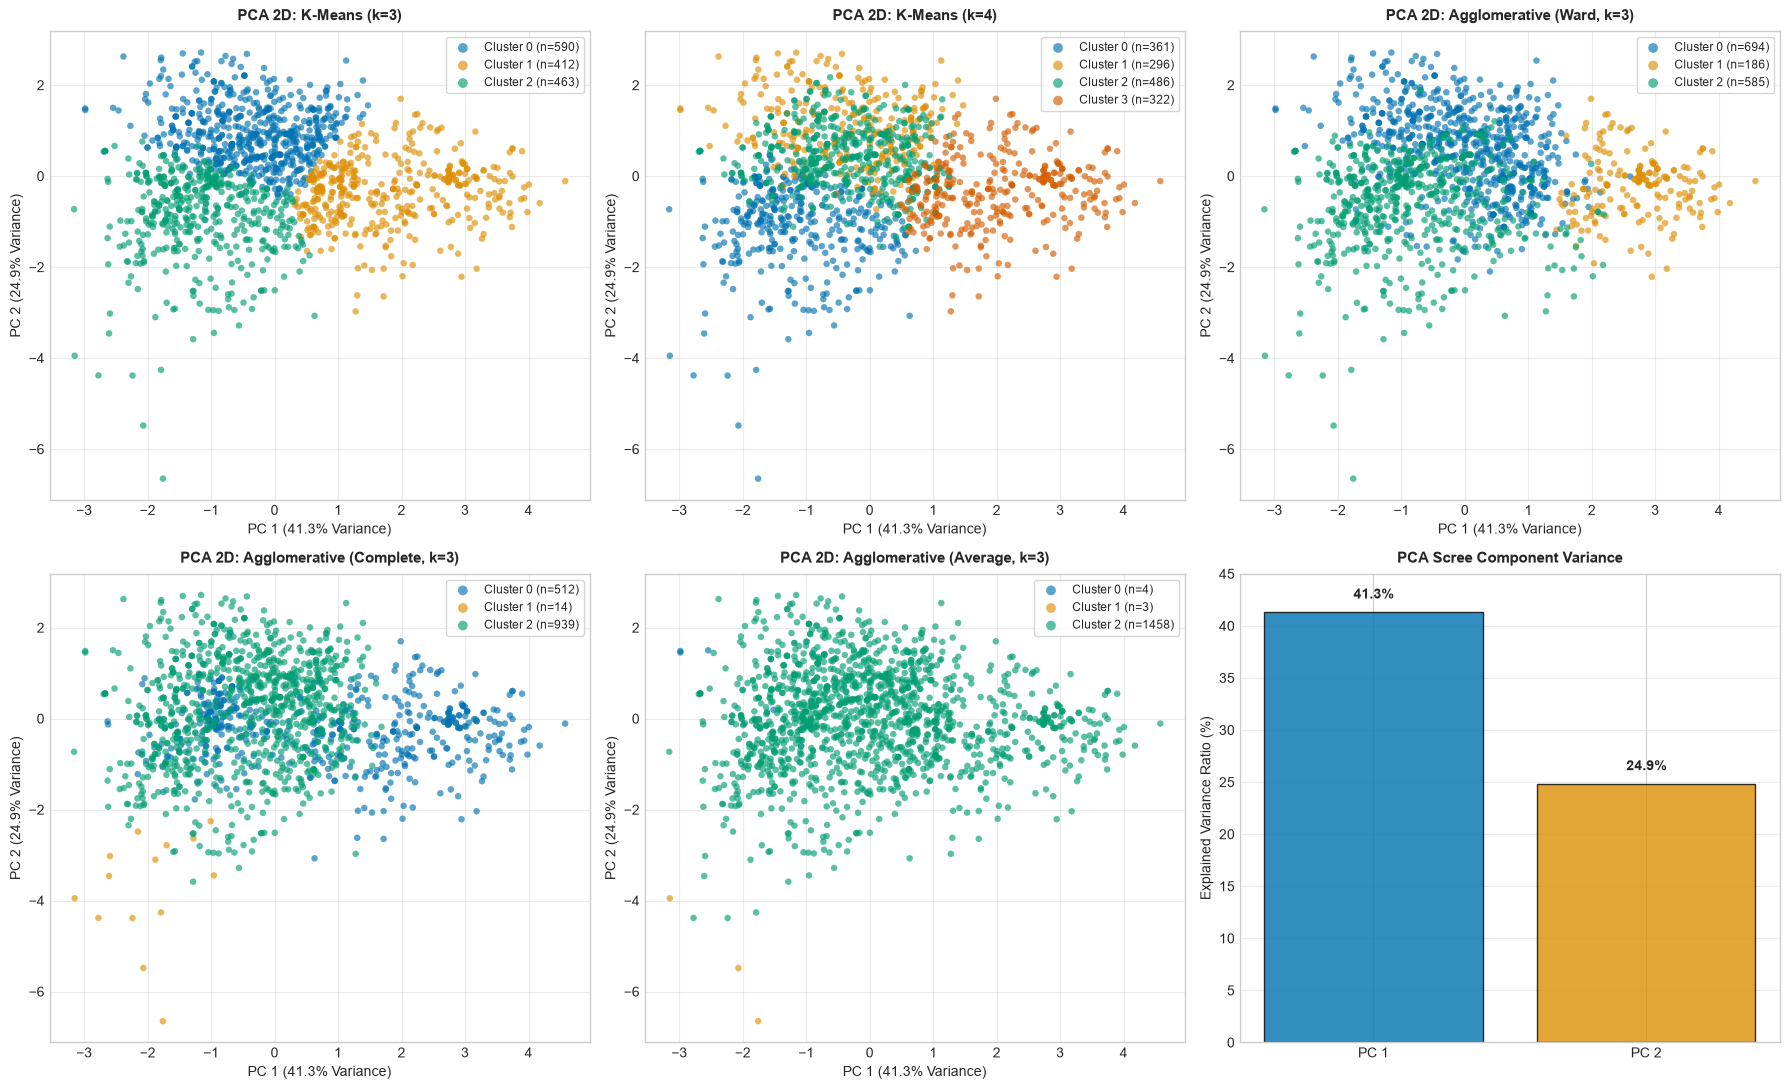

In [20]:
# Generate PCA 2D Scatter Plots for EVERY algorithm
palette = sns.color_palette('colorblind')
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 11))
axes_flat = axes.flatten()

plot_configs = [
    ('K-Means (k=3)', labels_km3),
    ('K-Means (k=4)', labels_km4),
    ('Agglomerative (Ward, k=3)', agg_labels['ward']),
    ('Agglomerative (Complete, k=3)', agg_labels['complete']),
    ('Agglomerative (Average, k=3)', agg_labels['average'])
]

for idx, (title, labels) in enumerate(plot_configs):
    ax = axes_flat[idx]
    unique_labels = np.unique(labels)
    
    for l_idx, label_val in enumerate(unique_labels):
        mask = (labels == label_val)
        ax.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            c=[palette[l_idx % len(palette)]],
            label=f'Cluster {label_val} (n={mask.sum()})',
            alpha=0.65,
            edgecolor='none',
            s=22
        )
    
    ax.set_title(f"PCA 2D: {title}", fontsize=11, fontweight='bold', pad=8)
    ax.set_xlabel(f"PC 1 ({evr[0]*100:.1f}% Variance)", fontsize=10)
    ax.set_ylabel(f"PC 2 ({evr[1]*100:.1f}% Variance)", fontsize=10)
    ax.legend(loc='best', frameon=True, fontsize=8.5, markerscale=1.5)
    ax.grid(True, alpha=0.4)

# 6th subplot for summary PCA variance explanation
axes_flat[5].bar(
    ['PC 1', 'PC 2'],
    evr * 100,
    color=[palette[0], palette[1]],
    edgecolor='black',
    alpha=0.8
)
axes_flat[5].set_title("PCA Scree Component Variance", fontsize=11, fontweight='bold', pad=8)
axes_flat[5].set_ylabel("Explained Variance Ratio (%)", fontsize=10)
for p in axes_flat[5].patches:
    axes_flat[5].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2., p.get_height() + 1.0),
                          ha='center', va='bottom', fontsize=10, fontweight='bold')
axes_flat[5].set_ylim(0, 45)
axes_flat[5].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

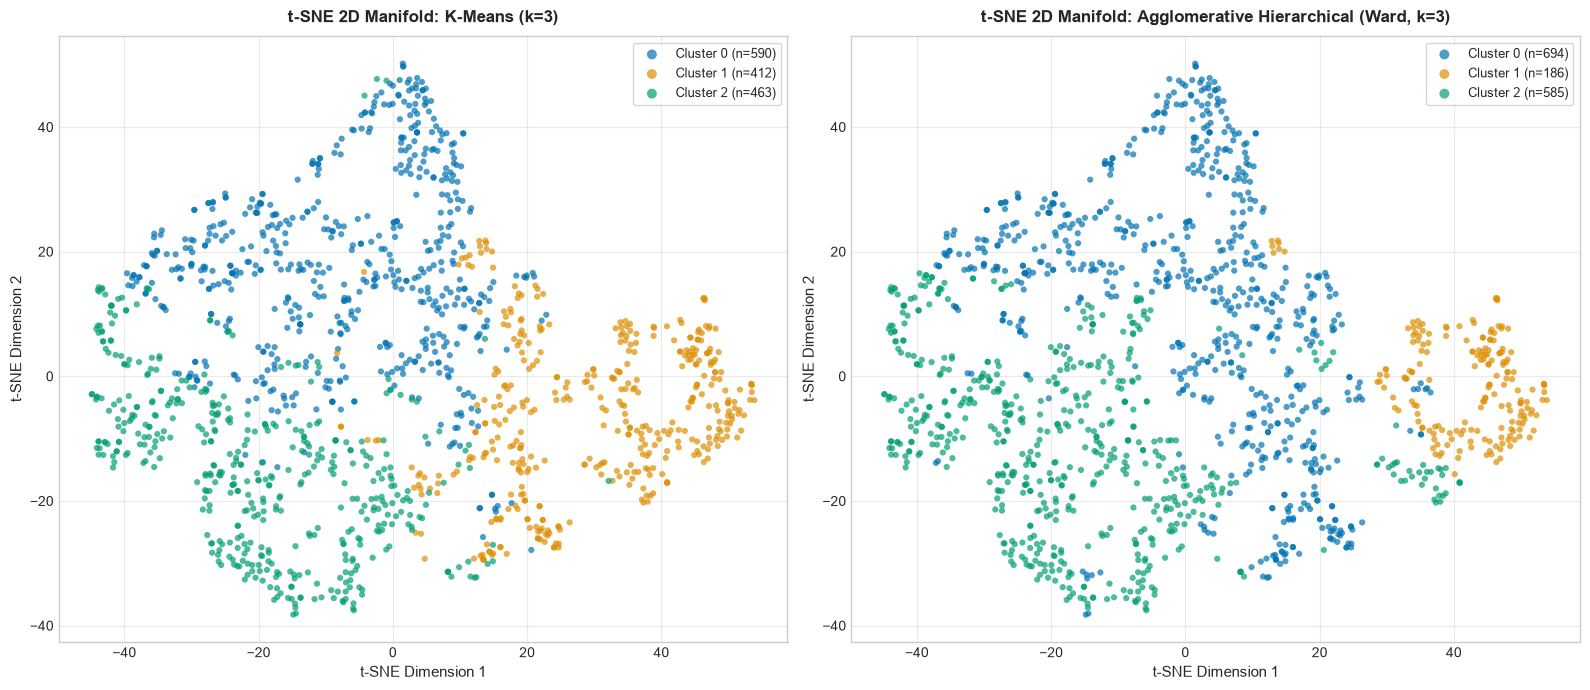

In [21]:
# Generate t-SNE 2D Scatter Plots for K-Means and Agglomerative Ward
fig, (ax_tsne1, ax_tsne2) = plt.subplots(1, 2, figsize=(16, 7))

# Plot t-SNE for K-Means (k=3)
for l_idx, label_val in enumerate(np.unique(labels_km3)):
    mask = (labels_km3 == label_val)
    ax_tsne1.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        c=[palette[l_idx % len(palette)]],
        label=f'Cluster {label_val} (n={mask.sum()})',
        alpha=0.7,
        edgecolor='none',
        s=20
    )
ax_tsne1.set_title("t-SNE 2D Manifold: K-Means (k=3)", fontsize=12, fontweight='bold', pad=10)
ax_tsne1.set_xlabel("t-SNE Dimension 1", fontsize=11)
ax_tsne1.set_ylabel("t-SNE Dimension 2", fontsize=11)
ax_tsne1.legend(loc='best', frameon=True, fontsize=9.5, markerscale=1.6)
ax_tsne1.grid(True, alpha=0.4)

# Plot t-SNE for Agglomerative Hierarchical (Ward)
for l_idx, label_val in enumerate(np.unique(agg_labels['ward'])):
    mask = (agg_labels['ward'] == label_val)
    ax_tsne2.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        c=[palette[l_idx % len(palette)]],
        label=f'Cluster {label_val} (n={mask.sum()})',
        alpha=0.7,
        edgecolor='none',
        s=20
    )
ax_tsne2.set_title("t-SNE 2D Manifold: Agglomerative Hierarchical (Ward, k=3)", fontsize=12, fontweight='bold', pad=10)
ax_tsne2.set_xlabel("t-SNE Dimension 1", fontsize=11)
ax_tsne2.set_ylabel("t-SNE Dimension 2", fontsize=11)
ax_tsne2.legend(loc='best', frameon=True, fontsize=9.5, markerscale=1.6)
ax_tsne2.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

### 7a. PCA Biplot — Feature Projection Vectors on Cluster Scatter
Overlays the original feature directions (red arrows) on the 2D PCA cluster scatter, showing which features drive the separation along each principal component.

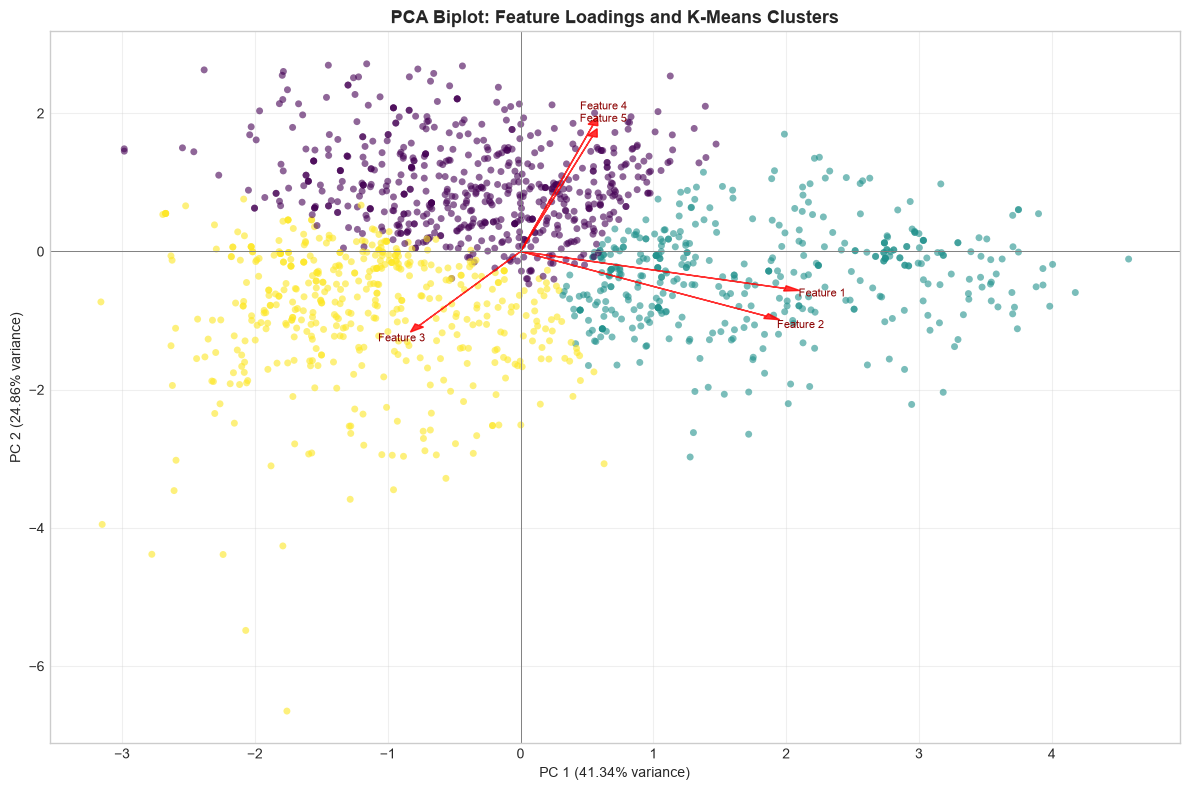

Saved: pca_biplot_feature_loadings.png


In [22]:

# ── 7a. PCA Biplot — Feature Projection Vectors on Cluster Scatter ──

import numpy as np
import matplotlib.pyplot as plt

# Feature names from the scaled dataset
feature_names = X_scaled.columns if hasattr(X_scaled, 'columns') else [
    f'Feature {i+1}' for i in range(X_scaled.shape[1])
]

# Calculate PCA feature loadings
loadings = pca.components_.T

# Create PCA biplot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot data points using K-Means labels
scatter = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_km3,
    cmap='viridis',
    alpha=0.6,
    s=25,
    edgecolors='none'
)

# Scale arrows for visualization
scale = min(
    np.ptp(X_pca[:, 0]),
    np.ptp(X_pca[:, 1])
) * 0.4

# Draw feature loading vectors
for i, feature in enumerate(feature_names):
    x_loading = loadings[i, 0] * scale
    y_loading = loadings[i, 1] * scale

    ax.arrow(
        0, 0,
        x_loading,
        y_loading,
        color='red',
        alpha=0.8,
        head_width=scale * 0.025,
        length_includes_head=True
    )

    ax.text(
        x_loading * 1.08,
        y_loading * 1.08,
        feature,
        color='darkred',
        fontsize=8,
        ha='center',
        va='center'
    )

ax.set_title(
    'PCA Biplot: Feature Loadings and K-Means Clusters',
    fontsize=13,
    fontweight='bold'
)
ax.set_xlabel(f'PC 1 ({evr[0]*100:.2f}% variance)')
ax.set_ylabel(f'PC 2 ({evr[1]*100:.2f}% variance)')

ax.grid(True, alpha=0.3)
ax.axhline(0, color='gray', linewidth=0.7)
ax.axvline(0, color='gray', linewidth=0.7)

plt.tight_layout()

# Save and display the figure
plt.savefig(
    'pca_biplot_feature_loadings.png',
    dpi=150,
    bbox_inches='tight'
)
plt.show()

print('Saved: pca_biplot_feature_loadings.png')


**Observation (PCA Biplot):**
The price vectors (`log_actual_price`, `log_discounted_price`) point in almost the same direction, so they carry nearly the same information and pull the upper-right cluster toward high-priced products. 
The review-volume and rating vectors (`log_rating_count`, `rating_popularity_score`, `rating_num`) point toward the lower right, marking the popular, well-reviewed products. 
`discount_percentage_num` points the opposite way (left), which matches the left-hand cluster of heavily discounted products. 
Short arrows near the origin would mean a feature contributes little to the two displayed components.

## 8. Market Segment Interpretation (Section 3.3 Post-hoc Ground-Truth Validation)
Inverse-transforms cluster centroids back to original physical units to profile product archetypes. Identifies natural demographic regimes across pricing, discounts, and customer engagement.

In [23]:
# Compute original feature median and mean profiles per K-Means (k=3) cluster
df_analyzed = df.copy()
df_analyzed['Cluster'] = labels_km3

profile_features = ['discounted_price_clean', 'actual_price_clean', 'discount_percentage_clean', 'discount_amount', 'rating_clean', 'rating_count_clean']
cluster_profiles_median = df_analyzed.groupby('Cluster')[profile_features].median()
cluster_profiles_count = df_analyzed.groupby('Cluster').size()
cluster_profiles_median['Product_Count'] = cluster_profiles_count
cluster_profiles_median['Population_%'] = (cluster_profiles_count / len(df_analyzed)) * 100

# Assign taxonomy / persona names based on median parameters
taxonomy_map = {
    0: "High-Volume Everyday Accessories & Tech Staples",
    1: "Premium Flagship Tech & Smart Appliances",
    2: "Emerging / Deep-Discount Clearance Items"
}
cluster_profiles_median['Taxonomy_Classification'] = cluster_profiles_median.index.map(taxonomy_map)

cols_ordered = ['Taxonomy_Classification', 'Product_Count', 'Population_%', 'discounted_price_clean', 'actual_price_clean', 'discount_percentage_clean', 'discount_amount', 'rating_clean', 'rating_count_clean']
cluster_profiles_median = cluster_profiles_median[cols_ordered]
cluster_profiles_median.columns = ['Market Segment Taxonomy', 'Product Count', 'Population %', 'Selling Price (₹)', 'Actual Price (₹)', 'Discount %', 'Cash Savings (₹)', 'Rating (1-5)', 'Review Count']

print("             PRODUCT CATALOG TAXONOMIC CLUSTER PROFILE (MEDIAN PROPERTIES)")
print(cluster_profiles_median.round(2).to_string())
cluster_profiles_median.round(2)

             PRODUCT CATALOG TAXONOMIC CLUSTER PROFILE (MEDIAN PROPERTIES)
                                 Market Segment Taxonomy  Product Count  Population %  Selling Price (₹)  Actual Price (₹)  Discount %  Cash Savings (₹)  Rating (1-5)  Review Count
Cluster                                                                                                                                                                             
0        High-Volume Everyday Accessories & Tech Staples            590         40.27              599.0            1099.0        43.0             467.0           4.2       12153.0
1               Premium Flagship Tech & Smart Appliances            412         28.12             5149.0            9999.0        40.0            4000.0           4.1        7269.5
2               Emerging / Deep-Discount Clearance Items            463         31.60              349.0             999.0        62.0             710.0           4.0         903.0


,Market Segment Taxonomy,Product Count,Population %,Selling Price (₹),Actual Price (₹),Discount %,Cash Savings (₹),Rating (1-5),Review Count
Cluster,,,,,,,,,
0,High-Volume Everyday Accessories & Tech Staples,590,40.27,599.0,1099.0,43.0,467.0,4.2,12153.0
1,Premium Flagship Tech & Smart Appliances,412,28.12,5149.0,9999.0,40.0,4000.0,4.1,7269.5
2,Emerging / Deep-Discount Clearance Items,463,31.60,349.0,999.0,62.0,710.0,4.0,903.0


In [24]:
# Cross-tabulation: Clusters vs Ground-Truth Main Categories
# Ensure main_category is set on df_analyzed
if 'main_category' not in df_analyzed.columns:
    df_analyzed['main_category'] = df_analyzed['category'].str.split('|').str[0].str.strip()

print('Cross-Tabulation: Discovered Clusters vs Ground-Truth Retail Categories:')
pd.crosstab(df_analyzed['Cluster'].map(taxonomy_map), df_analyzed['main_category'], margins=True)


Cross-Tabulation: Discovered Clusters vs Ground-Truth Retail Categories:


main_category,Car&Motorbike,Computers&Accessories,Electronics,Health&PersonalCare,Home&Kitchen,HomeImprovement,MusicalInstruments,OfficeProducts,Toys&Games,All
Cluster,,,,,,,,,,
Emerging / Deep-Discount Clearance Items,0,177,140,1,143,1,0,1,0,463
High-Volume Everyday Accessories & Tech Staples,0,251,154,0,151,1,2,30,1,590
Premium Flagship Tech & Smart Appliances,1,25,232,0,154,0,0,0,0,412
All,1,453,526,1,448,2,2,31,1,1465


## 8. Product Segment Growth & Trend Analysis
Visualising how each discovered cluster compares across key commercial dimensions — price ladder, discount aggression, review momentum, and value-for-money — to surface which segment is growing in market attractiveness.

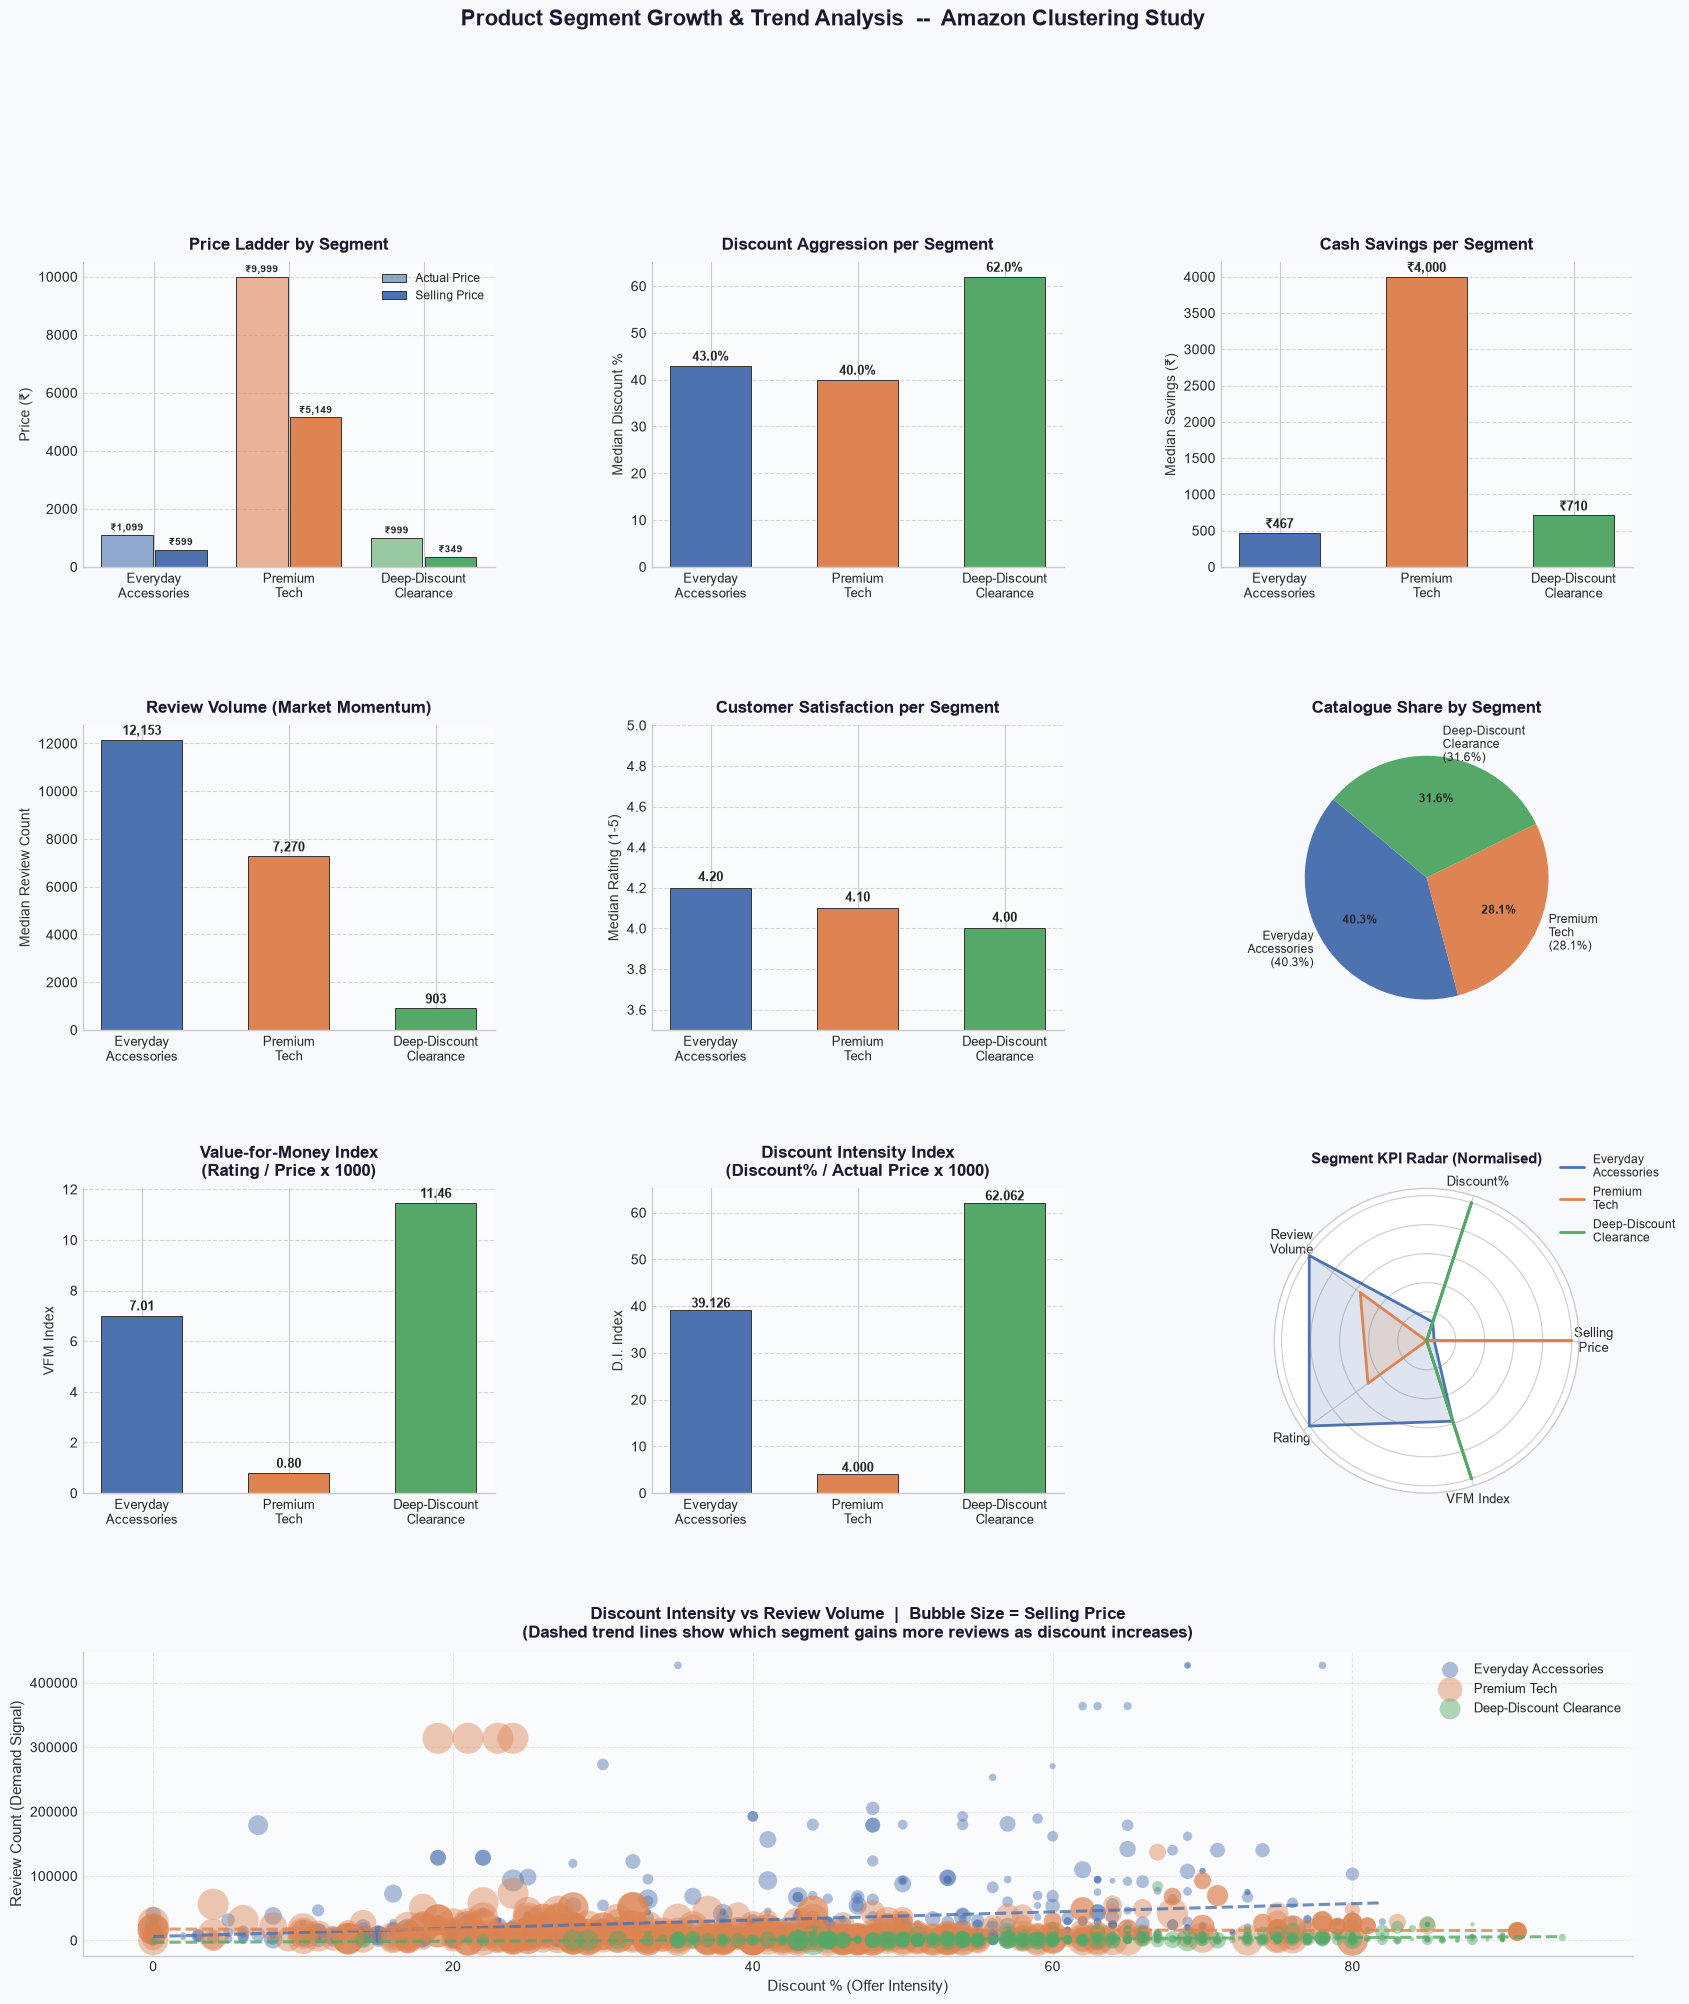

Figure saved: segment_trend_analysis.png


In [25]:
#  SECTION 8: Product Segment Growth & Trend Analysis 
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

#  Rebuild cluster profile for plotting 
df_trend = df.copy()
df_trend['Cluster'] = labels_km3

segment_names = {
    0: 'Everyday\nAccessories',
    1: 'Premium\nTech',
    2: 'Deep-Discount\nClearance'
}
COLORS = ['#4C72B0', '#DD8452', '#55A868']

feat_cols = [
    'discounted_price_clean', 'actual_price_clean',
    'discount_percentage_clean', 'discount_amount',
    'rating_clean', 'rating_count_clean'
]
med = df_trend.groupby('Cluster')[feat_cols].median()
cnt = df_trend.groupby('Cluster').size()
med['count'] = cnt
med['pop_pct'] = cnt / cnt.sum() * 100

clusters = med.index.tolist()
labels_short = [segment_names[c] for c in clusters]

#  Figure layout (4 rows x 3 cols) 
fig = plt.figure(figsize=(20, 22), facecolor='#F7F9FC')
gs = gridspec.GridSpec(4, 3, figure=fig, hspace=0.52, wspace=0.38)

def style_ax(ax, title, ylabel, xlabel=''):
    ax.set_title(title, fontsize=12, fontweight='bold', pad=9, color='#1a1a2e')
    ax.set_ylabel(ylabel, fontsize=10, color='#333')
    ax.set_xlabel(xlabel, fontsize=10, color='#333')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', linestyle='--', alpha=0.45, color='#aaa')
    ax.set_facecolor('#FAFBFD')

x = np.arange(len(clusters))
bw = 0.55

# Plot 1: Price Ladder
ax1 = fig.add_subplot(gs[0, 0])
b1 = ax1.bar(x - 0.2, med['actual_price_clean'], width=0.38,
             color=[c + '99' for c in ['#4C72B0','#DD8452','#55A868']],
             edgecolor='#333', linewidth=0.7, label='Actual Price')
b2 = ax1.bar(x + 0.2, med['discounted_price_clean'], width=0.38,
             color=COLORS, edgecolor='#333', linewidth=0.7, label='Selling Price')
ax1.set_xticks(x); ax1.set_xticklabels(labels_short, fontsize=9)
for bar in list(b1) + list(b2):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
             f'\u20b9{bar.get_height():,.0f}', ha='center', va='bottom', fontsize=7.5, fontweight='bold')
ax1.legend(fontsize=8.5, framealpha=0.7)
style_ax(ax1, 'Price Ladder by Segment', 'Price (\u20b9)')

# Plot 2: Discount %
ax2 = fig.add_subplot(gs[0, 1])
bars2 = ax2.bar(x, med['discount_percentage_clean'], width=bw,
                color=COLORS, edgecolor='#333', linewidth=0.7)
ax2.set_xticks(x); ax2.set_xticklabels(labels_short, fontsize=9)
for bar in bars2:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
style_ax(ax2, 'Discount Aggression per Segment', 'Median Discount %')

# Plot 3: Cash Savings
ax3 = fig.add_subplot(gs[0, 2])
bars3 = ax3.bar(x, med['discount_amount'], width=bw,
                color=COLORS, edgecolor='#333', linewidth=0.7)
ax3.set_xticks(x); ax3.set_xticklabels(labels_short, fontsize=9)
for bar in bars3:
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
             f'\u20b9{bar.get_height():,.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
style_ax(ax3, 'Cash Savings per Segment', 'Median Savings (\u20b9)')

# Plot 4: Review Volume
ax4 = fig.add_subplot(gs[1, 0])
bars4 = ax4.bar(x, med['rating_count_clean'], width=bw,
                color=COLORS, edgecolor='#333', linewidth=0.7)
ax4.set_xticks(x); ax4.set_xticklabels(labels_short, fontsize=9)
for bar in bars4:
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
             f'{bar.get_height():,.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
style_ax(ax4, 'Review Volume (Market Momentum)', 'Median Review Count')

# Plot 5: Rating
ax5 = fig.add_subplot(gs[1, 1])
bars5 = ax5.bar(x, med['rating_clean'], width=bw,
                color=COLORS, edgecolor='#333', linewidth=0.7)
ax5.set_xticks(x); ax5.set_xticklabels(labels_short, fontsize=9)
ax5.set_ylim(3.5, 5.0)
for bar in bars5:
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
style_ax(ax5, 'Customer Satisfaction per Segment', 'Median Rating (1-5)')

# Plot 6: Pie — Catalogue Share
ax6 = fig.add_subplot(gs[1, 2])
wedges, texts, autotexts = ax6.pie(
    med['count'],
    labels=[f'{s}\n({v:.1f}%)' for s, v in zip(labels_short, med['pop_pct'])],
    colors=COLORS, autopct='%1.1f%%', startangle=140,
    pctdistance=0.65, textprops={'fontsize': 8.5}
)
for at in autotexts: at.set_fontweight('bold')
ax6.set_title('Catalogue Share by Segment', fontsize=12, fontweight='bold', pad=9, color='#1a1a2e')

# Plot 7: VFM Index
ax7 = fig.add_subplot(gs[2, 0])
vfm = med['rating_clean'] / med['discounted_price_clean'] * 1000
bars7 = ax7.bar(x, vfm, width=bw, color=COLORS, edgecolor='#333', linewidth=0.7)
ax7.set_xticks(x); ax7.set_xticklabels(labels_short, fontsize=9)
for bar in bars7:
    ax7.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
style_ax(ax7, 'Value-for-Money Index\n(Rating / Price x 1000)', 'VFM Index')

# Plot 8: Discount Intensity
ax8 = fig.add_subplot(gs[2, 1])
pdr = med['discount_percentage_clean'] / med['actual_price_clean'] * 1000
bars8 = ax8.bar(x, pdr, width=bw, color=COLORS, edgecolor='#333', linewidth=0.7)
ax8.set_xticks(x); ax8.set_xticklabels(labels_short, fontsize=9)
for bar in bars8:
    ax8.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
             f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
style_ax(ax8, 'Discount Intensity Index\n(Discount% / Actual Price x 1000)', 'D.I. Index')

# Plot 9: Radar Chart
ax9 = fig.add_subplot(gs[2, 2], polar=True)
kpi_labels = ['Selling\nPrice', 'Discount%', 'Review\nVolume', 'Rating', 'VFM Index']
kpi_raw = np.array([
    med['discounted_price_clean'].values,
    med['discount_percentage_clean'].values,
    med['rating_count_clean'].values,
    med['rating_clean'].values,
    vfm.values
])
kpi_norm = (kpi_raw - kpi_raw.min(axis=1, keepdims=True)) / (
    kpi_raw.max(axis=1, keepdims=True) - kpi_raw.min(axis=1, keepdims=True) + 1e-9)
N = len(kpi_labels)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]
for ci, cid in enumerate(clusters):
    vals = kpi_norm[:, ci].tolist() + [kpi_norm[0, ci]]
    ax9.plot(angles, vals, color=COLORS[ci], linewidth=2, label=segment_names[cid])
    ax9.fill(angles, vals, color=COLORS[ci], alpha=0.18)
ax9.set_xticks(angles[:-1]); ax9.set_xticklabels(kpi_labels, fontsize=9)
ax9.set_yticklabels([])
ax9.set_title('Segment KPI Radar (Normalised)', fontsize=11, fontweight='bold', pad=18, color='#1a1a2e')
ax9.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=8.5, framealpha=0.8)

# Plot 10: Scatter + trend lines
ax10 = fig.add_subplot(gs[3, :])
for ci, cid in enumerate(clusters):
    mask = df_trend['Cluster'] == cid
    ax10.scatter(
        df_trend.loc[mask, 'discount_percentage_clean'],
        df_trend.loc[mask, 'rating_count_clean'],
        c=COLORS[ci],
        s=df_trend.loc[mask, 'discounted_price_clean'].clip(upper=5000) / 10,
        alpha=0.45, edgecolors='none',
        label=segment_names[cid].replace('\n', ' ')
    )
for ci, cid in enumerate(clusters):
    mask = df_trend['Cluster'] == cid
    xd = df_trend.loc[mask, 'discount_percentage_clean'].values
    yd = df_trend.loc[mask, 'rating_count_clean'].values
    z = np.polyfit(xd, yd, 1)
    p = np.poly1d(z)
    xs = np.linspace(xd.min(), xd.max(), 100)
    ax10.plot(xs, p(xs), color=COLORS[ci], linewidth=2.2, linestyle='--', alpha=0.8)
ax10.set_xlabel('Discount % (Offer Intensity)', fontsize=11, color='#333')
ax10.set_ylabel('Review Count (Demand Signal)', fontsize=11, color='#333')
ax10.set_title(
    'Discount Intensity vs Review Volume  |  Bubble Size = Selling Price\n'
    '(Dashed trend lines show which segment gains more reviews as discount increases)',
    fontsize=12, fontweight='bold', pad=10, color='#1a1a2e'
)
ax10.legend(fontsize=9.5, framealpha=0.8, loc='upper right')
ax10.spines[['top', 'right']].set_visible(False)
ax10.grid(linestyle='--', alpha=0.4)
ax10.set_facecolor('#FAFBFD')

fig.suptitle(
    'Product Segment Growth & Trend Analysis  --  Amazon Clustering Study',
    fontsize=16, fontweight='bold', color='#1a1a2e', y=0.995
)
plt.savefig('segment_trend_analysis.png', dpi=150, bbox_inches='tight', facecolor='#F7F9FC')
plt.show()
print('Figure saved: segment_trend_analysis.png')


## 9. Multi-Metric Line Graphs & Feature Profile Analysis
Line-based visualisations showing how clustering metrics evolve across k, feature distributions per cluster, and comparative trend lines across segments.

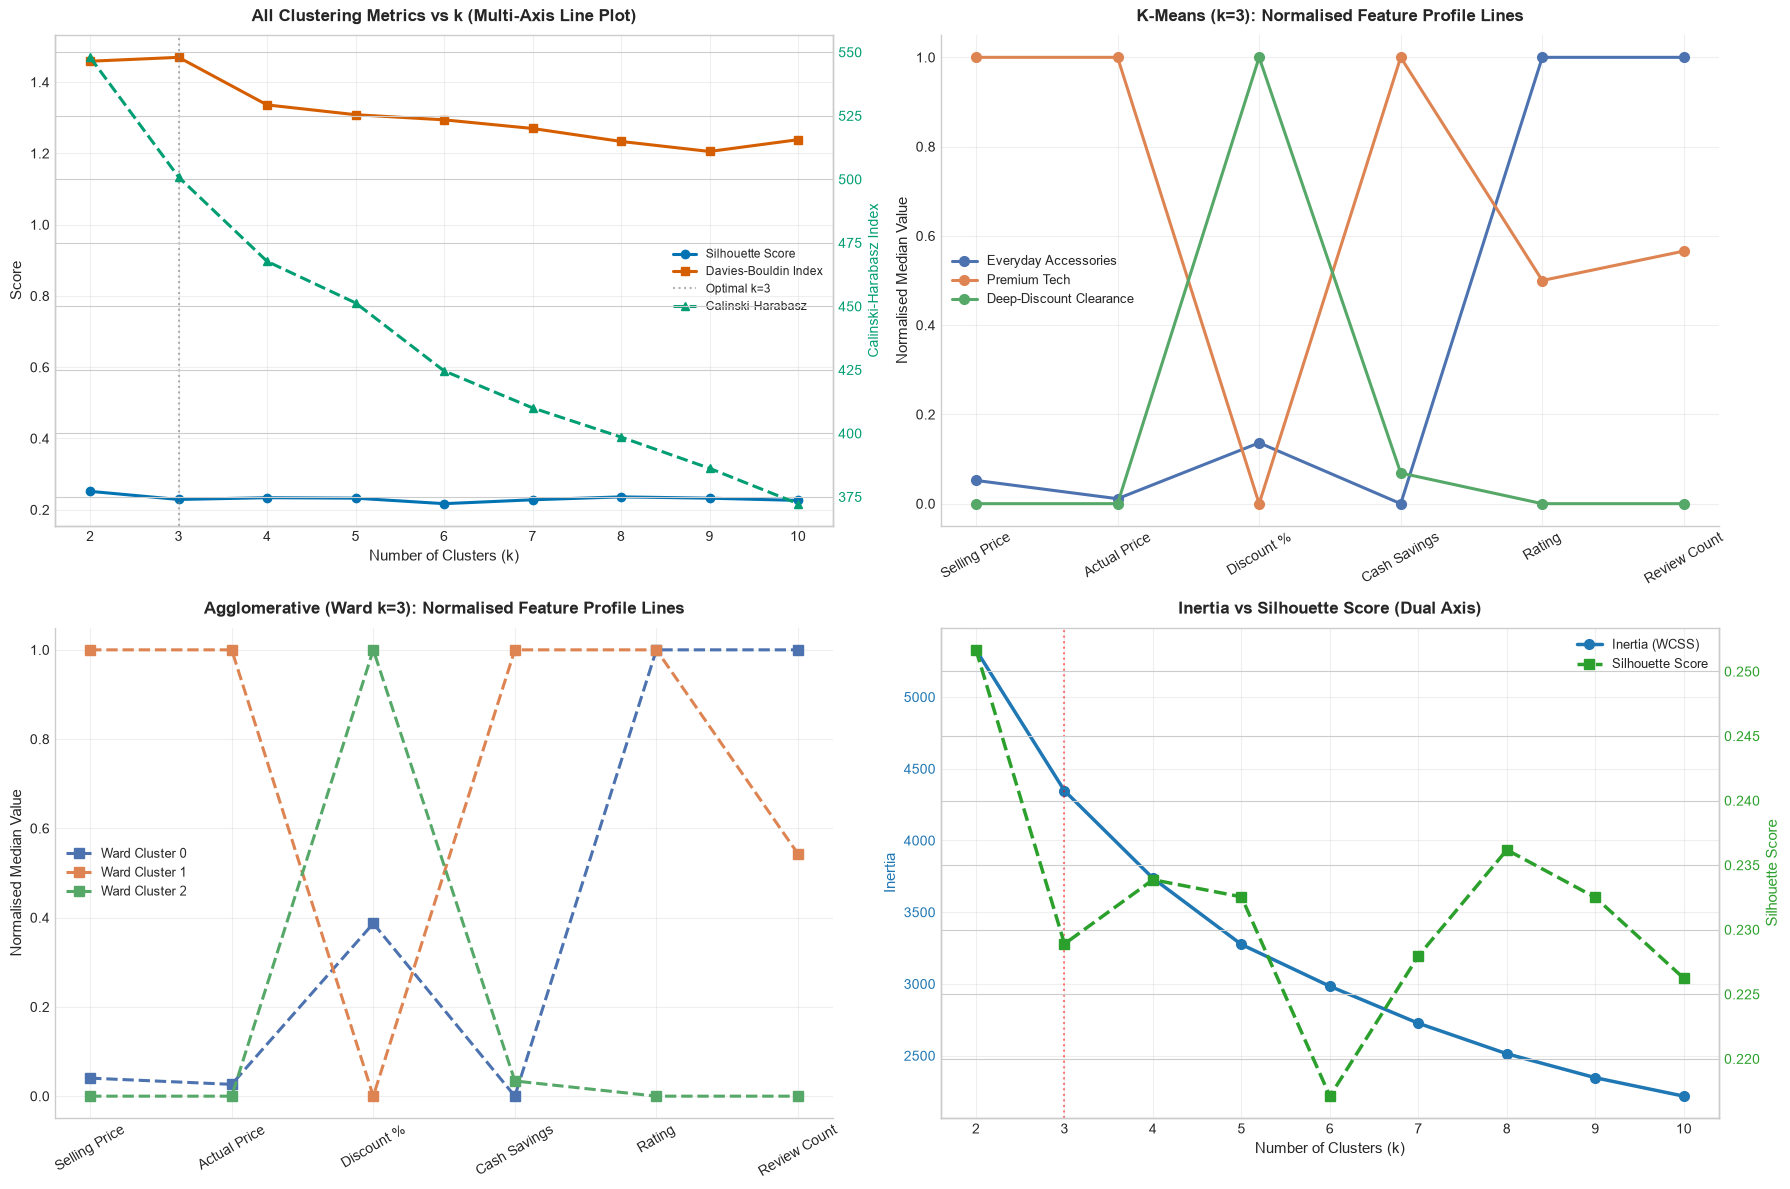

Saved: line_graphs_analysis.png


In [26]:
#  SECTION 9: Line Graphs & Feature Profile Analysis 

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
palette = sns.color_palette('colorblind')

#  Plot 1: All 4 Clustering Metrics vs k (multi-line) 
ax = axes[0, 0]
ax.plot(list(k_range), silhouette_scores_k, marker='o', linewidth=2.2, markersize=6,
        color=palette[0], label='Silhouette Score')
ax.plot(list(k_range), davies_bouldin_scores_k, marker='s', linewidth=2.2, markersize=6,
        color=palette[3], label='Davies-Bouldin Index')
ax_twin = ax.twinx()
ax_twin.plot(list(k_range), calinski_harabasz_scores_k, marker='^', linewidth=2.2, markersize=6,
             color=palette[2], label='Calinski-Harabasz', linestyle='--')
ax_twin.set_ylabel('Calinski-Harabasz Index', fontsize=10, color=palette[2])
ax_twin.tick_params(axis='y', labelcolor=palette[2])
ax.axvline(x=3, color='gray', linestyle=':', alpha=0.6, label='Optimal k=3')
ax.set_xlabel('Number of Clusters (k)', fontsize=11)
ax.set_ylabel('Score', fontsize=11)
ax.set_title('All Clustering Metrics vs k (Multi-Axis Line Plot)', fontsize=12, fontweight='bold', pad=10)
ax.set_xticks(list(k_range))
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax_twin.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8.5, framealpha=0.8, loc='center right')
ax.grid(True, alpha=0.3)
ax.spines[['top']].set_visible(False)

#  Plot 2: Feature Profile Lines per Cluster (K-Means k=3) 
ax2 = axes[0, 1]
df_line = df.copy()
df_line['Cluster'] = labels_km3
feat_names = ['discounted_price_clean','actual_price_clean','discount_percentage_clean',
              'discount_amount','rating_clean','rating_count_clean']
pretty = ['Selling Price','Actual Price','Discount %','Cash Savings','Rating','Review Count']
med_line = df_line.groupby('Cluster')[feat_names].median()
med_norm = (med_line - med_line.min()) / (med_line.max() - med_line.min() + 1e-9)
COLORS = ['#4C72B0', '#DD8452', '#55A868']
seg_names = {0: 'Everyday Accessories', 1: 'Premium Tech', 2: 'Deep-Discount Clearance'}
for ci, (idx_c, row) in enumerate(med_norm.iterrows()):
    ax2.plot(pretty, row.values, marker='o', linewidth=2.2, markersize=7,
             color=COLORS[ci], label=seg_names[idx_c])
ax2.set_title('K-Means (k=3): Normalised Feature Profile Lines', fontsize=12, fontweight='bold', pad=10)
ax2.set_ylabel('Normalised Median Value', fontsize=11)
ax2.legend(fontsize=9, framealpha=0.8)
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='x', rotation=30)
ax2.spines[['top','right']].set_visible(False)

#  Plot 3: Agglomerative Ward Feature Profile Lines 
ax3 = axes[1, 0]
df_agg_line = df.copy()
df_agg_line['Cluster'] = agg_labels['ward']
med_agg = df_agg_line.groupby('Cluster')[feat_names].median()
med_agg_norm = (med_agg - med_agg.min()) / (med_agg.max() - med_agg.min() + 1e-9)
for ci, (idx_c, row) in enumerate(med_agg_norm.iterrows()):
    ax3.plot(pretty, row.values, marker='s', linewidth=2.2, markersize=7,
             color=COLORS[ci], label=f'Ward Cluster {idx_c}', linestyle='--')
ax3.set_title('Agglomerative (Ward k=3): Normalised Feature Profile Lines', fontsize=12, fontweight='bold', pad=10)
ax3.set_ylabel('Normalised Median Value', fontsize=11)
ax3.legend(fontsize=9, framealpha=0.8)
ax3.grid(True, alpha=0.3)
ax3.tick_params(axis='x', rotation=30)
ax3.spines[['top','right']].set_visible(False)

#  Plot 4: Inertia Curve + Silhouette overlaid (dual-axis line) 
ax4 = axes[1, 1]
color_inertia = '#1f77b4'
color_sil = '#2ca02c'
ax4.plot(list(k_range), inertias, marker='o', linewidth=2.5, markersize=7,
         color=color_inertia, label='Inertia (WCSS)')
ax4.set_xlabel('Number of Clusters (k)', fontsize=11)
ax4.set_ylabel('Inertia', fontsize=11, color=color_inertia)
ax4.tick_params(axis='y', labelcolor=color_inertia)
ax4b = ax4.twinx()
ax4b.plot(list(k_range), silhouette_scores_k, marker='s', linewidth=2.5, markersize=7,
          color=color_sil, linestyle='--', label='Silhouette Score')
ax4b.set_ylabel('Silhouette Score', fontsize=11, color=color_sil)
ax4b.tick_params(axis='y', labelcolor=color_sil)
ax4.axvline(x=3, color='red', linestyle=':', alpha=0.5)
ax4.set_xticks(list(k_range))
lines_a, labels_a = ax4.get_legend_handles_labels()
lines_b, labels_b = ax4b.get_legend_handles_labels()
ax4.legend(lines_a + lines_b, labels_a + labels_b, fontsize=9, framealpha=0.8)
ax4.set_title('Inertia vs Silhouette Score (Dual Axis)', fontsize=12, fontweight='bold', pad=10)
ax4.grid(True, alpha=0.3)
ax4.spines[['top']].set_visible(False)

plt.tight_layout()
plt.savefig('line_graphs_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: line_graphs_analysis.png')


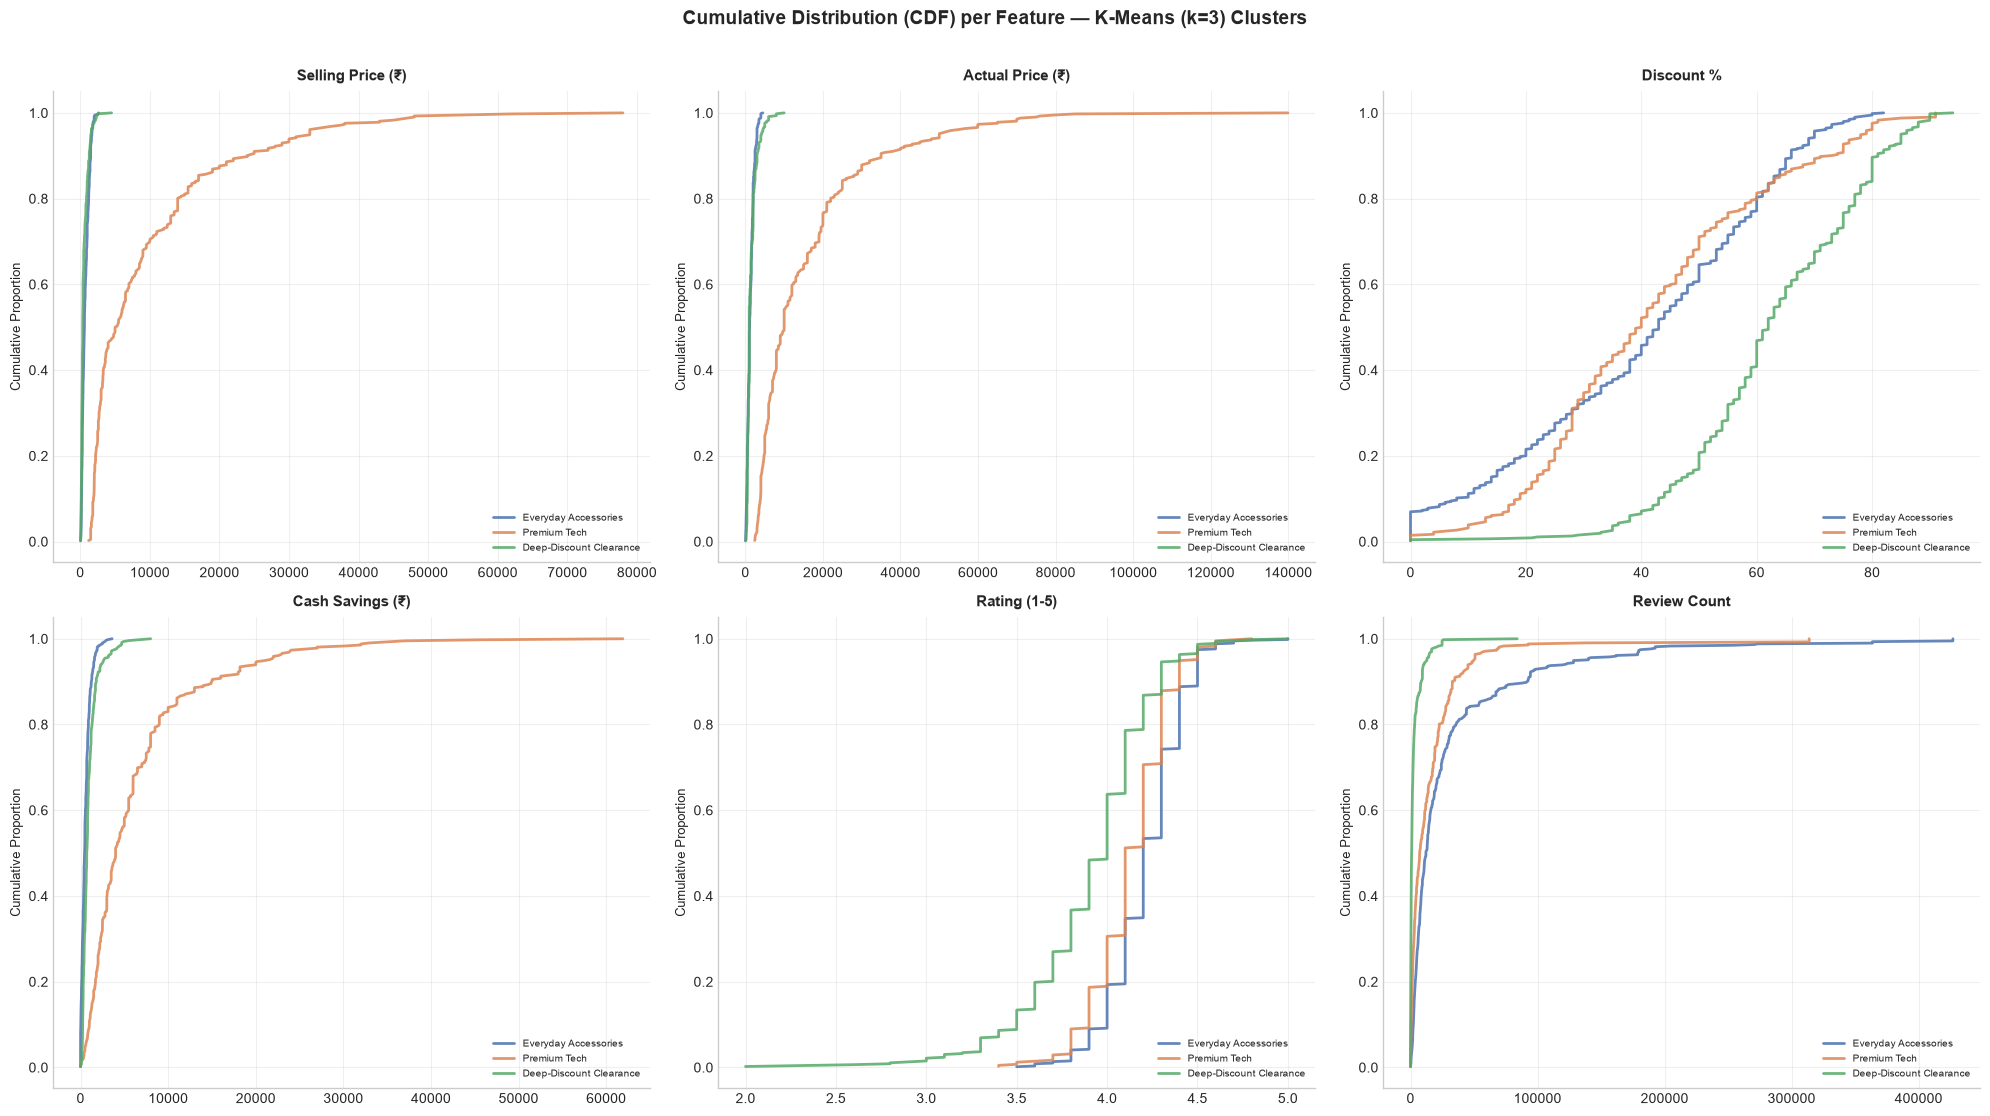

Saved: cdf_lines_per_cluster.png


In [27]:
#  Cumulative Distribution Lines: Features by Cluster \
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
axes_flat = axes.flatten()

feat_names = ['discounted_price_clean','actual_price_clean','discount_percentage_clean',
              'discount_amount','rating_clean','rating_count_clean']
pretty = ['Selling Price (\u20b9)','Actual Price (\u20b9)','Discount %',
          'Cash Savings (\u20b9)','Rating (1-5)','Review Count']
COLORS = ['#4C72B0', '#DD8452', '#55A868']
seg_names = {0: 'Everyday Accessories', 1: 'Premium Tech', 2: 'Deep-Discount Clearance'}

df_cdf = df.copy()
df_cdf['Cluster'] = labels_km3

for fi, (feat, ptitle) in enumerate(zip(feat_names, pretty)):
    ax = axes_flat[fi]
    for ci in sorted(df_cdf['Cluster'].unique()):
        vals = df_cdf.loc[df_cdf['Cluster'] == ci, feat].dropna().sort_values()
        cdf_y = np.arange(1, len(vals) + 1) / len(vals)
        ax.plot(vals, cdf_y, linewidth=2, color=COLORS[ci],
                label=seg_names[ci], alpha=0.85)
    ax.set_title(ptitle, fontsize=11, fontweight='bold', pad=8)
    ax.set_ylabel('Cumulative Proportion', fontsize=9)
    ax.legend(fontsize=7.5, framealpha=0.7, loc='lower right')
    ax.grid(True, alpha=0.3)
    ax.spines[['top','right']].set_visible(False)

fig.suptitle('Cumulative Distribution (CDF) per Feature — K-Means (k=3) Clusters',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('cdf_lines_per_cluster.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: cdf_lines_per_cluster.png')
